The purpose of this repo is to asses the viability of different imaging schemes for our clock apparatus. This includes either 399nm or 556nm imaging in a variety of different tweezers.

States:
1S0 and 3P0 (plus 3P1 for the 556 nm imaging, and 1P1 for blue imaging)

Light:
- 460.862 nm tweezers: the clock array (`clock_trap`; the other option is 459.596 nm, the 1S0–3P0 magic wavelength I calculate here)
- 532 nm tweezers: the imaging array for blue and green imaging
- 517.85135nm for tweezers for alternate imaging array for blue imaging
- 780 nm tweezers: the alternative green imaging array
- 399 nm or 556 nm light on the imaging array nearby

In [1]:
####################### JUST IMPORTS AND CONSTANT ########################

import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
from sympy.physics.wigner import wigner_6j

""" 
constants
"""
pi = np.pi
c = sp.constants.c
epsilon_0 = sp.constants.epsilon_0
hbar = sp.constants.hbar
h = sp.constants.h
dm_au = sp.constants.physical_constants["atomic unit of electric dipole mom."][0]
t_au = sp.constants.physical_constants["atomic unit of time"][0]
alpha_au = 1.64877727436*1e-41 # 1 au in Cm^2/V

In [2]:
class state(object):
    def __init__(self, L, S, J):
        '''State for which we are calculating the polarizability or light shift.'''
        self.L = L
        self.S = S
        self.J = J

In [3]:
class transition(object): # to be clear WN here is k/2\pi
    def __init__(self, WN, Gamma, J): 
        '''wavenumber of transition in cm-1; decay rate in MHz; J of final state'''
        self.omega = 2 * np.pi * c * WN * 1e2 #transition freq in rad/s
        self.Gamma = 2 * np.pi * Gamma * 1e6 #decay rate in rad/s
        self.J = J #J of final state

    def I_sat(self):
        '''Saturation intensity (W/m^2), two-level atom: hbar Gamma omega^3 / (12 pi c^2).'''
        return hbar * self.Gamma * self.omega**3 / (12*pi*c**2)

Reduced matrix element:
$$
| \langle {J}||\mathbf{d}|| {J'} \rangle | = \sqrt{\frac{3\pi\epsilon_0\hbar c^3 }
{\omega_{J'J}^3 } \frac{2J' +1}{2J+1}\Gamma_{J'J} }
$$


In [4]:
def dm(transition, state):
    '''Reduced matrix element for a transition between J->J' states '''
    return np.sqrt( 
            3*np.pi * epsilon_0 * hbar * c**3 / transition.omega**3 
            * (2*transition.J + 1) / (2*state.J + 1) * transition.Gamma 
           )

Polarizability:
$$\alpha_J(\omega) = \sum_{n'J'}\frac{2\omega_{n'J'J}| \langle {J}||\mathbf{d}|| {J'} \rangle |^2}{3\hbar(\omega_{n'J'J}^2-\omega^2)}$$

In [5]:
def alpha(transitions, state): #polarizability
    return lambda omega: sum(
        [2*t.omega*(dm(t, state))**2 / 3 / hbar / (t.omega**2-omega**2)
        for t in transitions.values()])

## RECALL LAMBDA FUNCTIONS RETURN A FUNCTION TO ACT ON SOME OMEGA
## LOOKS LIKE alpha(transitions, state)(omega) will give the polarizability at a given omega

Light shift per laser beam intensity $I$:
$$V_{ac}/I = -\frac{1}{2\epsilon_0 c}\alpha_J(\omega) = - \sum_{n'J'}\frac{\omega_{n'J'J}| \langle {J}||\mathbf{d}|| {J'} \rangle |^2}{3\hbar\epsilon_0 c(\omega_{n'J'J}^2-\omega^2)}$$

In [6]:
def Vac(transitions, state): #light shift per unit of intensity
    # JUST A FACTOR TIMES ALPHA IDK WHY DIFFERENT METHOD (FROM GAURAV REPO)
    return lambda omega: sum(
        [-t.omega*(dm(t, state))**2 / 3 / hbar / epsilon_0 / c / (t.omega**2-omega**2)
        for t in transitions.values()])

## RECALL LAMBDA FUNCTIONS RETURN A FUNCTION TO ACT ON SOME OMEGA
## SO Vac(transitions, state)(omega) will give the light shift per unit of intensity at a given omega

In [7]:
# energies: NIST ASD (cm^-1). Decay rates Gamma/2pi (MHz): NIST transition rates A, except 1P1, where the measured
# 5.464 ns lifetime (Takasu et al., PRL 93, 123202 (2004)) is used; NIST's A = 1.92e8 /s is 5% higher than it
transition_from_1S0 = {

"6s6p 3P1": transition(17992.007, 0.183, 1),    # NIST A = 1.15e6 /s
# "6s6p 1P1": transition(25068.222, 29.127, 1), # moved below to separate resonant and non-resonant transitions
"(7/2,5/2)J=1": transition(28857.014, 10.870, 1) # NIST A = 6.83e7 /s (was 11.052)
}

t1P1 = transition(25068.222, 29.127, 1) # NIST energy (was 25068.2581, from the Yb reference data paper)

Vac_offset_1S0 = -0.8*h/1e4 ## from Yb reference paper
alpha_offset_1S0 = -Vac_offset_1S0 * (2*epsilon_0*c)

_3P0WN = 17288.439

transition_from_3P0 = {
    
"5d6s 3D1": transition(24489.102-_3P0WN, 0.308, 1),   
"6d6s 3D1": transition(39808.72-_3P0WN, 4.081, 1),

"6s7s 3S1": transition(32694.692-_3P0WN, 1.516, 1), 
"6s8s 3S1": transition(41615.04-_3P0WN, 0.625, 1), 

#added to accound for transitions
"empirical": transition(43880.305-_3P0WN, 22.889, 1), # from Yb reference paper
}

In [8]:
ground = state(0, 0, 0)
metastable = state(1, 1, 0)

In [9]:
# _lambda = np.linspace(420e-9, 1800e-9, 1000)
# _lambda = 398.910844e-9 # from yb reference data paper
# omega = 2*np.pi*c/_lambda
omega = t1P1.omega # the 1P1 line (NIST energy)

Vac_1S0_nonres = Vac(transition_from_1S0, ground)(omega) + Vac_offset_1S0
alpha_1S0_nonres = alpha(transition_from_1S0, ground)(omega) + alpha_offset_1S0

Vac_3P0 = Vac(transition_from_3P0, metastable)(omega)
alpha_3P0 = alpha(transition_from_3P0, metastable)(omega)

print(f"Vac_1S0 = {Vac_1S0_nonres:.3e} J/(W/m^2)")
print(f"Vac_3P0 = {Vac_3P0:.3e} J/(W/m^2)")
print(f"alpha_1S0 = {alpha_1S0_nonres:.3e} J/(V/m)^2")
print(f"alpha_3P0 = {alpha_3P0:.3e} J/(V/m)^2")
print(f"alpha_3P0 = {alpha_3P0/alpha_au:.3e} a.u.") # VALIDITY CHECK

Vac_1S0 = -3.153e-37 J/(W/m^2)
Vac_3P0 = -1.223e-36 J/(W/m^2)
alpha_1S0 = 1.674e-39 J/(V/m)^2
alpha_3P0 = 6.495e-39 J/(V/m)^2
alpha_3P0 = 3.939e+02 a.u.


Now we actually want to understand the degree to which these shifts occur.

We are taking I/I_sat = 40 from https://arxiv.org/pdf/2507.01011 (falconi fast imaging).

We calculate for $$I_{sat} = \frac{\pi h c\Gamma}{3\lambda^3}$$

In [10]:
s = 40 #I/I_sat = 40 form falconi paper
I_sat = t1P1.I_sat() #W/m^2
print(f"I_Sat: {I_sat/10:.3e} mW/cm^2")
peak_intensity = s * I_sat
print(f"Intensity = {peak_intensity/10:.3e} mW/cm^2")

I_Sat: 5.997e+01 mW/cm^2
Intensity = 2.399e+03 mW/cm^2


Initially we considered a 20x10 array in a space of 80x40um (4um separation) and a separation of 45um between regions which is plotted is seen in Obsidian.

Now, we do blue and green imaging with an array of 50x10 (500 atoms, 200x40um) in both the imaging and the clock zone, with a sepearation of 450um between the zones.


In [11]:
pitch = 4e-6
X,Y = np.meshgrid(67e-6 + pitch*np.arange(10), pitch*(np.arange(20)-9.5)) #m; OUR GRID
# print(X)
# print(Y)

## Top-hat beam model (CONVOLVE GAUSSIAN + TOP-HAT)

Model the shaped beam as a perfectly sharp top-hat blurred by the optics' focus spot (a rectangle smoothed by a Gaussian). That gives error-function edges:
$$f(x) = \frac{1}{2}\left[\mathrm{erfc}\left(\frac{|x|-a}{\sqrt{2}\,\sigma}\right) - \mathrm{erfc}\left(\frac{|x|+a}{\sqrt{2}\,\sigma}\right)\right]$$

- $a$: half-width at 50% intensity
- $\sigma$: edge blur; the 10–90% edge width is $2.56\,\sigma$
- Peak value 1

To check the model, digitize the vendor's example profile (210 μm flat region) and fit it.

In [12]:
from scipy.special import erfc

def tophat_1d(x, a, sigma):
    '''Top-hat profile with 50% half-width a and Gaussian-blurred edges of rms width sigma. Peak value 1.
    Written with erfc so the far tail stays accurate (an erf difference rounds to 0 below ~1e-16).'''
    x = np.abs(x)
    return 0.5*(erfc((x - a)/(np.sqrt(2)*sigma)) - erfc((x + a)/(np.sqrt(2)*sigma)))

In [13]:
# vendor's example line profile (210 um flat region), saved from the datasheet plot
vendor_img = plt.imread("figures/vendor_tophat_x_profile.png")[..., :3]

# pixel -> data calibration, read off the plot's gridlines
col_x0, px_per_um = 329, 0.92      # x = 0 um at column 329; gridlines 100 um apart are 92 px apart
row_I1, row_I0 = 17, 322           # intensity 1 at row 17, intensity 0 at row 322
def x_of_col(col): return (col - col_x0) / px_per_um
def I_of_row(row): return (row_I0 - row) / (row_I0 - row_I1)

# the curve is the only bluish thing in the image (the pink fill and gray lines are not)
blueness = np.clip(vendor_img[..., 2] - vendor_img[..., 0], 0, None)
mask = blueness > 0.06
mask[:row_I1 - 2] = False; mask[row_I0 + 3:] = False     # keep inside the axes box
mask[:, :46] = False; mask[:, 612:] = False
rows, cols = np.nonzero(mask)
weights = blueness[rows, cols]

points = []
for side in (-1, 1):               # steep edges: one point per pixel row on each side
    for r in np.unique(rows):
        sel = (rows == r) & (np.sign(x_of_col(cols)) == side) & (np.abs(x_of_col(cols)) > 100)
        if sel.any():
            points.append((x_of_col(np.average(cols[sel], weights=weights[sel])), I_of_row(r)))
for col in np.unique(cols):        # flat top and flat bottom: one point per pixel column
    if abs(x_of_col(col)) < 100 or abs(x_of_col(col)) > 220:
        sel = cols == col
        points.append((x_of_col(col), I_of_row(np.average(rows[sel], weights=weights[sel]))))
x_data, I_data = np.array(sorted(points)).T
print(f"{len(x_data)} points digitized")

825 points digitized


a = 137.4 +/- 0.0 um   (50% half-width)
sigma = 16.08 +/- 0.06 um   (10-90% edge = 41.2 um)
50% point sits 2.02 sigma outside the 105 um flat edge
rms residual = 0.013


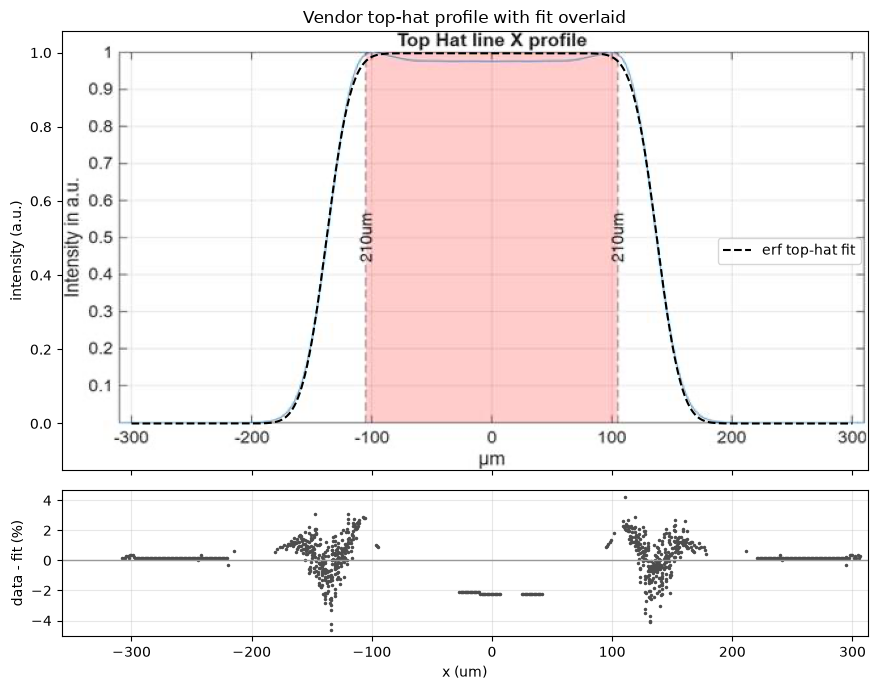

In [14]:
from scipy.optimize import curve_fit

def tophat_fit_model(x, A, a, sigma, x0):
    '''Amplitude A, 50% half-width a, edge width sigma, center offset x0 (all lengths in um).'''
    return A * tophat_1d(x - x0, a, sigma)

popt, pcov = curve_fit(tophat_fit_model, x_data, I_data, p0=[1, 140, 20, 0])
perr = np.sqrt(np.diag(pcov))
A_fit, a_fit, sigma_fit, x0_fit = popt
resid = I_data - tophat_fit_model(x_data, *popt)
print(f"a = {a_fit:.1f} +/- {perr[1]:.1f} um   (50% half-width)")
print(f"sigma = {sigma_fit:.2f} +/- {perr[2]:.2f} um   (10-90% edge = {2.563*sigma_fit:.1f} um)")
print(f"50% point sits {(a_fit - 105)/sigma_fit:.2f} sigma outside the 105 um flat edge")
print(f"rms residual = {np.sqrt(np.mean(resid**2)):.3f}")

# overlay the fit on the vendor plot, with residuals underneath
H, W = vendor_img.shape[:2]
extent = [x_of_col(-0.5), x_of_col(W - 0.5), I_of_row(H - 0.5), I_of_row(-0.5)]
fig, (ax, ax_res) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1]})
ax.imshow(vendor_img, extent=extent, aspect="auto")
x_plot = np.linspace(-300, 300, 1201)
ax.plot(x_plot, tophat_fit_model(x_plot, *popt), "k--", lw=1.5, label="erf top-hat fit")
ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
ax.set_ylabel("intensity (a.u.)")
ax.set_title("Vendor top-hat profile with fit overlaid")
ax.legend(loc="center right")

ax_res.plot(x_data, 100*resid, ".", color="0.3", ms=3)
ax_res.axhline(0, color="0.6", lw=1)
ax_res.set_xlabel("x (um)"); ax_res.set_ylabel("data - fit (%)")
ax_res.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Fit result: $a = 137.4$ μm, $\sigma = 16.1$ μm (10–90% edge = 41 μm). The 50% point sits $2.0\,\sigma$ outside the edge of the 210 μm flat region. Residuals stay within ±4% on the edges (about one pixel of the image) and are −2% at the center, from the small dip in the vendor profile that the model leaves out.

BTW residuals are poportional to the peak intensity. ALSO the noise around the steep peaks is a function of resolution claude things (hard for angles). Residual RMS is 1.3%. NOTE: ALSO WE SHOULD SWEEP A UNIFORM BACKGROUND OF 10^-8 to 10_3 TO SEE WHAT HURST. THIS IS NOT A "DESIGNED FALL OFF" THIS IS BACKGROUND LEAKAGE DUE TO IMPERFECTIONS OF ALL SORTS.

Caveat: the plot only resolves intensity down to about 1%. Below that, the erf tail is an extrapolation, and real optics usually have a scattered-light floor well above it, so model that floor separately (`eps_bg`).

### Top-hat on our grid

The fixed optic makes a flat region of 40 μm (x) × 160 μm (y), centered on the imaging array (40 μm × 280 μm for the imaging tasks, whose arrays are 200 μm tall); x is the side facing the clock array. The edge blur is scaled from the vendor fit above ($\sigma = 16.1$ μm for a 210 μm flat region), keeping the 50% point $2.0\,\sigma$ outside the flat region. We don't yet know how the edge scales, so there are two cases:

- `long_side`: both edges scale with the long side (280 μm for the imaging tasks) (one blur for the whole pattern, as if the vendor example were simply shrunk)
- `own_side`: each edge scales with its own side, so the 40 μm side gets a 7× sharper edge

`eps_bg` is a uniform background floor (fraction of peak) for light leaking from imperfections; 0 means the ideal designed shape only.

In [15]:
W_x, W_y = 40e-6, 160e-6                 # flat region of the mask, m; x faces the clock array
edge_case = "long_side"                  # "long_side" or "own_side"
eps_bg = 0                               # background floor as a fraction of peak; sweep 1e-8 to 1e-3 later

def tophat_edges(edge_case, W=(W_x, W_y)):
    '''50% half-widths and edge blurs (a_x, sigma_x, a_y, sigma_y), in m, scaled from the vendor fit, for a flat region W (m).'''
    w_x, w_y = W
    sigma_per_width = sigma_fit / 210        # vendor fit: sigma = 16.1 um for a 210 um flat region
    edge_offset = (a_fit - 105) / sigma_fit  # vendor fit: 50% point sits ~2.0 sigma outside the flat region
    if edge_case == "long_side":             # one blur for the whole pattern, set by the long side
        sigma_x = sigma_y = sigma_per_width * max(w_x, w_y)
    elif edge_case == "own_side":            # each edge scales with its own side
        sigma_x, sigma_y = sigma_per_width * w_x, sigma_per_width * w_y
    else:
        raise ValueError(f"unknown edge_case {edge_case!r}")
    return w_x/2 + edge_offset*sigma_x, sigma_x, w_y/2 + edge_offset*sigma_y, sigma_y

def tophat_intensity(X, Y, edge_case, eps_bg=0.0, W=(W_x, W_y)):
    '''Top-hat intensity (W/m^2) at positions X, Y (m) for flat region W, plus a uniform background floor eps_bg (fraction of peak).'''
    a_x, sigma_x, a_y, sigma_y = tophat_edges(edge_case, W)
    return peak_intensity * (tophat_1d(X, a_x, sigma_x) * tophat_1d(Y, a_y, sigma_y) + eps_bg)

a_x, sigma_x, a_y, sigma_y = tophat_edges(edge_case)
frac = tophat_intensity(X, Y, edge_case, eps_bg) / peak_intensity
print(f"edge case '{edge_case}': sigma_x = {sigma_x*1e6:.2f} um (10-90% edge {2.563*sigma_x*1e6:.1f} um), 50% point at x = {a_x*1e6:.1f} um")
print(f"imaging-array corner (18, 38) um sees {tophat_intensity(18e-6, 38e-6, edge_case)/peak_intensity:.3f} of peak")
print(f"clock array sees {frac.min():.1e} to {frac.max():.1e} of peak (max s = {s*frac.max():.2g})")

edge case 'long_side': sigma_x = 12.25 um (10-90% edge 31.4 um), 50% point at x = 44.7 um
imaging-array corner (18, 38) um sees 0.985 of peak
clock array sees 9.8e-07 to 3.4e-02 of peak (max s = 1.4)


Resonant 1S0 light shift, `shift_resonant` (two-level atom, valid only for $s \ll 1$):
$$\delta\nu_{res} = \frac{\Gamma}{2\pi}\,\frac{s}{4}\,\frac{x}{1+x^2}, \qquad x = \frac{2\Delta}{\Gamma}, \qquad s = \frac{I}{I_{sat}}$$

- $\Delta = \omega_{laser} - \omega_{atom}$ (rad/s), $\Gamma$ = decay rate of the resonant line: $2\pi \times 29.1$ MHz for 1P1 here; the 556 nm tasks reuse it with 3P1's $2\pi \times 183$ kHz
- Zero on resonance, largest at $\Delta = \pm\Gamma/2$; red detuning ($\Delta < 0$) lowers 1S0
- Far from resonance ($|\Delta| \gg \Gamma$) it becomes $\frac{1}{2\pi}\frac{s\,\Gamma^2}{8\Delta}$, the same $1/\Delta$ behavior as the $V_{ac}$ formula above

In [16]:
def shift_resonant(s_local, Delta, Gamma):
    '''1S0 light shift (Hz) from the resonant line with decay rate Gamma (rad/s).
    s_local = I/I_sat at the atom; Delta = laser minus atom resonance, rad/s. Only valid for s << 1.'''
    x = 2*Delta/Gamma
    return (Gamma/(2*pi)) * s_local * x / (4*(1 + x**2))

Photon scattering rate from 1S0, `scatter_rate` (two-level atom, including saturation, valid for any $s$):
$$R_{sc} = \frac{\Gamma}{2}\,\frac{s}{1 + s + x^2}, \qquad x = \frac{2\Delta}{\Gamma}$$

- Units: photons per second
- Largest on resonance; saturates at $\Gamma/2$ for $s \gg 1$
- For $s \ll 1$ it becomes $\frac{\Gamma}{2}\frac{s}{1+x^2}$, and $2\pi\,\delta\nu_{1P1}/R_{sc} = \Delta/\Gamma$: within a linewidth of resonance, scattering is as big as the shift

In [17]:
def scatter_rate(s_local, Delta, Gamma):
    '''Photons scattered per second by an atom in 1S0 from the resonant line with decay rate Gamma (rad/s).
    s_local = I/I_sat at the atom; Delta = laser minus atom resonance, rad/s. Includes saturation, valid for any s.'''
    x = 2*Delta/Gamma
    return (Gamma/2) * s_local / (1 + s_local + x**2)

In [18]:
Delta = 0 # blue imaging detuning (rad/s) from the imaged atoms' in-trap line: on resonance (not focusing on the light shift for now); was -t1P1.Gamma/2

## Green imaging: tweezer-induced detuning of the clock atoms

In task 2 the 556 nm light shines on the imaging array, in 532 nm tweezers (`green_trap`; 780 nm at the magic angle is the alternative), while the clock atoms stay in their own tweezers (460.862 nm, or 459.596 nm (my calculated magic here) with `clock_trap`). (Blue imaging, with its imaging array in 532 nm tweezers, has the same effect on the 399 nm line; see the 1P1 section after task 2.) Each tweezer shifts 1S0 and 3P1 by different amounts, which moves a 556 nm transition by
$$\delta\nu_{556} = -\left(\frac{\alpha_{3P1}}{\alpha_{1S0}} - 1\right)\frac{U}{h},$$
where $U$ is the 1S0 trap depth. Light tuned relative to the atoms it is meant for is therefore off resonance for the clock atoms by the difference of the two shifts. Because $\Gamma/2\pi$ is only 183 kHz, MHz-scale differences put the clock atoms many linewidths away, which cuts their scattering by the factor $1 + (2\Delta/\Gamma)^2$ in `scatter_rate`.

Polarizabilities: a sum over states. Energies are NIST values everywhere in the notebook (as tabulated by Tang, Yu, Jiang & Dong, [arXiv:1712.08888](https://arxiv.org/abs/1712.08888), Table 2; the (7/2,5/2) J = 1 state lies outside their calculation and comes straight from the NIST ASD). The reduced E1 matrix elements, and the core and "all other states" contributions, are Tang's (Table 4), except for the three 1S0 lines also defined at the top of the notebook (1P1, 3P1, (7/2,5/2)). Those come from the same transition objects, so each line has one value everywhere: 3P1 and (7/2,5/2) from NIST transition rates, 1P1 from its measured 5.464 ns lifetime (NIST's rate is 5% higher). The 1S0–3P1 element is the same on the 1S0 and 3P1 sides. 3P1 has a tensor part, so the shift depends on the excited state through $\langle J_z^2\rangle$: $\alpha = \alpha_S + \alpha_T\,\tfrac{3\cos^2\theta - 1}{2}\,(3\langle J_z^2\rangle - 2)$, with θ the angle between the linear tweezer polarization and the field. At low field, ¹⁷¹Yb $|F'=3/2, m_F'=\pm 1/2\rangle$ has $\langle J_z^2\rangle = 1/3$. The shift is linear in cos²θ, so θ = 0° and 90° bound every other angle, and the worst case over them is used.

Checks: the code reproduces the paper's static polarizabilities and its 1S0–3P1 magic wavelengths (including the measured 1035.68 nm π magic wavelength, Zheng et al., [arXiv:2011.06759](https://arxiv.org/abs/2011.06759)), and the Cooling project's independent 780 nm numbers.

Inputs: clock array in 460.862 nm tweezers (`clock_trap`; or 459.596 nm, the measured 1S0–3P0 magic wavelength, ¹⁷¹Yb Reference Data, Table 7), 230 μK deep; imaging array in 532 nm (or 780 nm) tweezers, 10 MHz deep (wavelengths taken as vacuum). ZEEMAN SHIFTS AREN'T CONSIDERED AS THIS IS WORST CASE SCENARIO.

**Task 2 (green imaging):** the light is +Γ from the imaged atoms' own resonance. It drives an $|m_F'| = 1/2$ sublevel of $F' = 3/2$ (π from $m_F = -1/2$ gives $m_F' = -1/2$), with $\langle J_z^2\rangle = 1/3$. At 532 nm no tweezer angle is magic for this state: 3P1 is trapped at 0.41–0.77 of the 1S0 depth, so the 532 nm trap moves the imaged atoms' line up by 2.3–5.9 MHz (13–32 Γ), and the light follows it. The 460.862 nm clock tweezers move the clock atoms' line down by 14.6–15.6 MHz, so the two add: Δ_clock = 93–118 Γ. At 459.596 nm, closer to the 3P1 → 6s6d ³D lines at 458 nm, 3P1 is trapped 6.5–7.3× harder than 1S0, the clock atoms' line moves down by 26.5–30.2 MHz, and Δ_clock = 158–198 Γ; the cell prints both. (460.862 nm is not magic for the clock transition in this model: α(3P0) and α(1S0) differ by about 4% there, and the model's own clock magic wavelength is 459.65 nm.) Both tweezer angles are searched (0° and 90° at 532 nm, 0°–90° at 460.862 nm) and the worst case is used. Not modeled: because the imaged atoms' line moves with depth, a 10% depth difference between imaging tweezers moves it 1–3 Γ, and an atom's motion in its tweezer broadens it. The alternative, `green_trap` = 780 nm at this state's magic angle (34.1°), leaves the imaged atoms' line in place (Δ_clock = 80–86 Γ).

In [19]:
from scipy.optimize import brentq

cm1_to_au = 4.556335252912e-6          # 1 cm^-1 in Hartree (au, ground state energy of hydrogen atom (not binding energy))
# energies: NIST ASD (cm^-1), as tabulated by Tang, Yu, Jiang & Dong, arXiv:1712.08888 (Table 2)
# reduced E1 matrix elements (a.u.): Tang's Table 4 (where Tables 3 and 4 differ, Table 4, which Tang sums), except
# the three 1S0 lines also defined above (transition_from_1S0, t1P1), which are taken from those objects
def _line(name, t): ## NOTE THIS IS JUST TO CONVERT EARLIER NOTATION
    '''(name, energy in cm^-1, J, RME in a.u.) for a 1S0 line defined above.'''
    return (name, t.omega/(2*pi*c*1e2), t.J, float(dm(t, ground)/dm_au))

pol_from_1S0 = [  # (upper state, energy, J, RME)
    _line("6s6p 1P1", t1P1), _line("6s6p 3P1", transition_from_1S0["6s6p 3P1"]),
    _line("4f13 5d 6s2 (7/2,5/2)1", transition_from_1S0["(7/2,5/2)J=1"]),
    ("6s7p 1P1", 40563.97, 1, 0.67), ("6s7p 3P1", 38174.17, 1, 0.08), ("6s8p 1P1", 44017.60, 1, 0.21),
    ("6s8p 3P1", 43659.38, 1, 0.014)]    # Table 3 rounds the last one to 0.01
## THESE ARE FROM TANG PAPER; WE CAN"T CALCULATE AS NIST DOESN"T HAVE \GAMMA for them
pol_other_1S0, pol_core = 2.04, 7.27    # "all other states" (static) and core contributions, a.u.
E_3P1 = 17992.007 # measured energy of E_3P1 from NIST
pol_from_3P1 = [  # (other state, energy, J, RME), CI+MBPT values; the 1S0 element is the same one as above
    ("6s2 1S0", 0.0, 0, pol_from_1S0[1][3]), ("5d6s 3D1", 24489.102, 1, 2.57), ("5d6s 3D2", 24751.948, 2, 4.45),
    ("5d6s 1D2", 27677.665, 2, 0.46), ("6s6d 3D1", 39808.72, 1, 1.57), ("6s6d 3D2", 39838.04, 2, 2.72),
    ("6s6d 1D2", 40061.51, 2, 0.53), ("6s7d 3D1", 44311.38, 1, 2.47), ("6s7d 3D2", 44313.05, 2, 1.67),
    ("6s7d 1D2", 44357.60, 2, 0.86), ("6s7s 3S1", 32694.692, 1, 3.47), ("6s7s 1S0", 34350.65, 0, 0.24),
    ("6s8s 3S1", 41615.04, 1, 1.00), ("6s8s 1S0", 41939.90, 0, 0.29),  # Table 3: 0.30
    ("6p2 3P0", 42436.91, 0, 2.59), ("6p2 3P1", 43805.42, 1, 0.18), ("6p2 3P2", 44760.37, 2, 2.92)]
pol_other_3P1 = 16.87 # FROM TANG PAPER

_E1 = np.array([E for _, E, _, _ in pol_from_1S0])*cm1_to_au # ENERGIES OF 1S0 transitions
_d1 = np.array([d for _, _, _, d in pol_from_1S0]) # RMEs of 1S0 transitions
_dE3 = (np.array([E for _, E, _, _ in pol_from_3P1]) - E_3P1)*cm1_to_au # ENERGIES of 3P1 transitions
_d3 = np.array([d for _, _, _, d in pol_from_3P1]) # RMEs of 3P1 transitions
_J3 = np.array([Ji for _, _, Ji, _ in pol_from_3P1]) # Js of 3P1 transitions
_tensor_w = (2*np.sqrt((2*5)/(3*2*3*5)) * (-1.0)**(_J3 + 1)                       # J = 1 prefactor and phase
             * np.array([float(wigner_6j(1, 1, int(Ji), 1, 1, 2)) for Ji in _J3]))

def pol_1S0(lam_nm): ## NOTE same exact formulas as \alpha above (just uses all the lines we have here)
    '''Dynamic polarizability of 1S0 (a.u.) at vacuum wavelength lam_nm (np.inf = static).'''
    w = (1e7/np.asarray(lam_nm, float)*cm1_to_au)[..., None]
    return (2/3*_d1**2*_E1/(_E1**2 - w**2)).sum(-1) + pol_other_1S0 + pol_core

def pol_3P1(lam_nm): ## NOTE same formulas as \alpha above for a_s but has a_t part
    '''Scalar and tensor dynamic polarizabilities of 3P1 (J = 1), a.u.'''
    w = (1e7/np.asarray(lam_nm, float)*cm1_to_au)[..., None]
    term = _d3**2*_dE3/(_dE3**2 - w**2) ### NOTE THIS IS JUST THE LAST BIG OF THE TENSOR FORM, AS WE KNOW
    return (2/9*term).sum(-1) + pol_other_3P1 + pol_core, (_tensor_w*term).sum(-1)

def pol_3P1_state(lam_nm, Jz2, theta_deg):
    '''Polarizability (a.u.) of a 3P1 state with <J_z^2> = Jz2, for linear tweezer polarization at theta to the field.'''
    aS, aT = pol_3P1(lam_nm)
    return aS + aT*(3*np.cos(np.radians(theta_deg))**2 - 1)/2 * (3*Jz2 - 2)
    # NOTE angle is between polarization vector of incident light and magnetic field direction 

def line556_shift_per_depth(lam_nm, Jz2, theta_deg):
    '''Shift of a 556 nm transition per unit 1S0 trap depth: delta_nu / (U/h) = -(alpha_3P1 / alpha_1S0 - 1).'''
    return -(pol_3P1_state(lam_nm, Jz2, theta_deg)/pol_1S0(lam_nm) - 1)

# checks against the paper: static values (its Table 4) and its 1S0-3P1 magic wavelengths
aS0, aT0 = pol_3P1(np.inf)
print(f"static: alpha(1S0) = {pol_1S0(np.inf):.1f} a.u. (paper 135), alpha_S(3P1) = {aS0:.1f} (paper 328), "
      f"alpha_T(3P1) = {aT0:.1f} (paper 24.1)")
lam_scan = np.linspace(560, 1600, 20801)
aS_scan, aT_scan = pol_3P1(lam_scan)
### THESE ARE ALL REFERENCING THE TANG PAPER
for MJ, paper in [(0, "612.9, 1035.7 (measured: 1035.68)"), (1, "858(12), 1036.0, 1517.68")]:
    ## THIS NEXT FORMULA IS BASICALLY JUST THE STATE SHIFT BUT WITH ANGLE = 0
    diff = pol_1S0(lam_scan) - (aS_scan + (3*MJ**2 - 2)*aT_scan)        # J basis, polarization along the axis
    flips = np.flatnonzero((np.sign(diff[:-1]) != np.sign(diff[1:])) & (np.abs(diff[:-1]) < 50) & (np.abs(diff[1:]) < 50))
    f = lambda l: float(pol_1S0(l) - (pol_3P1(l)[0] + (3*MJ**2 - 2)*pol_3P1(l)[1]))
    found = ", ".join(f"{brentq(f, lam_scan[i], lam_scan[i+1]):.1f}" for i in flips)
    print(f"magic wavelengths, |MJ| = {MJ}: {found} nm (paper: {paper} nm)")
# check against the Cooling project (same matrix elements, independent code) at 780 nm
aS780, aT780 = pol_3P1(780.0)
print(f"780 nm: alpha_S(3P1) = {aS780:.1f}, alpha_T(3P1) = {aT780:.1f}, alpha(1S0) = {float(pol_1S0(780.0)):.1f} a.u. "
      f"(Cooling project: 215.6, 71.9, 178.5)")

static: alpha(1S0) = 135.2 a.u. (paper 135), alpha_S(3P1) = 328.7 (paper 328), alpha_T(3P1) = 23.0 (paper 24.1)
magic wavelengths, |MJ| = 0: 613.0, 1035.8 nm (paper: 612.9, 1035.7 (measured: 1035.68) nm)
magic wavelengths, |MJ| = 1: 856.5, 1036.1, 1517.6 nm (paper: 858(12), 1036.0, 1517.68 nm)
780 nm: alpha_S(3P1) = 215.9, alpha_T(3P1) = 70.5, alpha(1S0) = 178.7 a.u. (Cooling project: 215.6, 71.9, 178.5)


460.862 nm: U(3P1)/U(1S0) = 4.035 at 0°, 4.248 at 90°, never magic
517.851 nm: U(3P1)/U(1S0) = 0.775 at 0°, 0.488 at 90°, never magic
532 nm: U(3P1)/U(1S0) = 0.770 at 0°, 0.414 at 90°, never magic
780 nm: U(3P1)/U(1S0) = 0.814 at 0°, 1.406 at 90°, magic at 34.1°


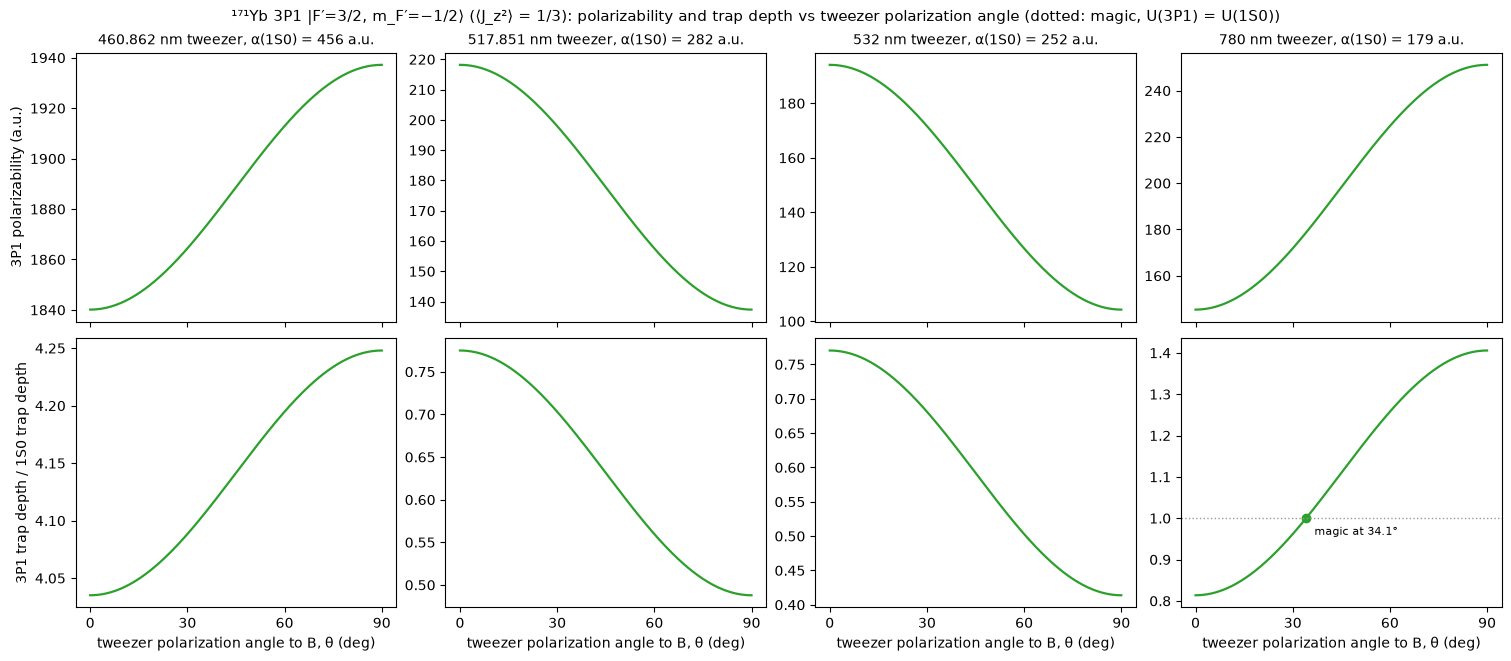

In [20]:
## HERE I want to calculate the effect of different angles on polarizability of our 3P1 state and also on the trap depth as a whole I guess?
# 3P1 polarizability and trap depth vs the tweezer's linear polarization angle to the field, at four tweezer wavelengths.
# 1S0 has no angle dependence (J = 0), so the 3P1 trap depth relative to 1S0 is alpha_3P1(theta) / alpha_1S0.
lams_plot = (460.862, 517.85135, 532.0, 780.0)          # tweezer wavelengths (nm, vacuum); 460.862 = clock array
Jz2_plot = 1/3                                      # |F'=3/2, mF' = -1/2> (pi from mF = -1/2)
theta = np.linspace(0, 90, 181)                     # tweezer polarization angle to the field (deg)

def magic_angle(lam_nm, Jz2):
    '''Angle (deg) at which a 3P1 state with <J_z^2> = Jz2 is trapped like 1S0, or None. The shift is linear in cos^2.'''
    aS, aT = pol_3P1(lam_nm)
    cos2 = float((2*(pol_1S0(lam_nm) - aS)/(aT*(3*Jz2 - 2)) + 1)/3)
    return float(np.degrees(np.arccos(np.sqrt(cos2)))) if 0 <= cos2 <= 1 else None

fig, axs = plt.subplots(2, len(lams_plot), figsize=(15, 6.5), sharex=True, layout="constrained")
for k, lam in enumerate(lams_plot):
    a_1S0 = float(pol_1S0(lam))
    a_3P1 = pol_3P1_state(lam, Jz2_plot, theta)
    axs[0, k].plot(theta, a_3P1, color="tab:green", lw=1.6)
    axs[1, k].plot(theta, a_3P1/a_1S0, color="tab:green", lw=1.6)
    th_m = magic_angle(lam, Jz2_plot)
    if th_m is not None:
        axs[1, k].plot(th_m, 1, "o", color="tab:green", ms=6)
        axs[1, k].annotate(f"magic at {th_m:.1f}°", (th_m, 1), xytext=(6, -12), textcoords="offset points", fontsize=8)
    print(f"{lam:g} nm: U(3P1)/U(1S0) = {a_3P1[0]/a_1S0:.3f} at 0°, {a_3P1[-1]/a_1S0:.3f} at 90°"
          + (f", magic at {th_m:.1f}°" if th_m is not None else ", never magic"))
    axs[1, k].set_ylim(axs[1, k].get_ylim())        # keep the curve's range: the magic line shows only where it falls inside
    axs[1, k].axhline(1, color="0.6", ls=":", lw=1)
    axs[0, k].set_title(f"{lam:g} nm tweezer, α(1S0) = {a_1S0:.0f} a.u.", fontsize=10)
    axs[1, k].set_xlabel("tweezer polarization angle to B, θ (deg)")
    axs[1, k].set_xticks([0, 30, 60, 90])
axs[0, 0].set_ylabel("3P1 polarizability (a.u.)")
axs[1, 0].set_ylabel("3P1 trap depth / 1S0 trap depth")
fig.suptitle("¹⁷¹Yb 3P1 |F′=3/2, m_F′=−1/2⟩ (⟨J_z²⟩ = 1/3): polarizability and trap depth vs tweezer polarization angle "
             "(dotted: magic, U(3P1) = U(1S0))", fontsize=11)
plt.show()

In [21]:
clock_traps = {"460.862 nm": 460.862,                # clock-array tweezer options (nm, vacuum)
               "459.596 nm (clock magic)": 459.596}  # measured 1S0-3P0 magic wavelength (171Yb Reference Data, Table 7)
clock_trap = "460.862 nm"                            # the clock-array tweezers both tasks use
lam_tweezer_clock, U_clock_uK = clock_traps[clock_trap], 230   # clock array: wavelength (nm, vacuum) and 1S0 trap depth (uK)
lam_tweezer_780, U_780_MHz = 780.0, 10.0           # the other green imaging array (`green_trap`): wavelength (nm), depth U/h (MHz)
lam_tweezer_517, U_517_MHz = 517.85135, 10.0      # alternate blue imaging array (see the intro)
lam_tweezer_532, U_532_MHz = 532.0, 10.0           # blue and green imaging arrays
U_clock_MHz = U_clock_uK * sp.constants.k * 1e-6 / h / 1e6
Gamma_556_MHz = transition_from_1S0["6s6p 3P1"].Gamma/(2*pi)/1e6
pol_angles = (0, 90)       # tweezer polarization to the field (deg); the shift is linear in cos^2, so these bound every angle


def worst_detuning(values):
    '''Closest-to-resonance detuning over the polarization corners; 0 if the range crosses resonance.'''
    values = np.asarray(values)
    return 0.0 if values.min() < 0 < values.max() else float(values[np.argmin(np.abs(values))])

print(f"1S0 polarizability: {float(pol_1S0(lam_tweezer_clock)):.1f} a.u. at {lam_tweezer_clock} nm, "
      f"{float(pol_1S0(lam_tweezer_780)):.1f} a.u. at {lam_tweezer_780} nm", f"{float(pol_1S0(lam_tweezer_517)):.1f} a.u. at {lam_tweezer_517} nm, "
      f"{float(pol_1S0(lam_tweezer_532)):.1f} a.u. at {lam_tweezer_532} nm")
print(f"trap depths: clock array {U_clock_uK} uK = {U_clock_MHz:.2f} MHz, 780 nm arrays {U_780_MHz} MHz", f"517 nm arrays {U_517_MHz} MHz", f"532 nm arrays {U_532_MHz} MHz")


# task 2, green imaging: the light is +Gamma from the imaged atoms' in-trap resonance
Jz2_img = 1/3                                      # driven sublevel |F'=3/2, mF' = -1/2> (pi from mF = -1/2)
th_780_img = magic_angle(lam_tweezer_780, Jz2_img) # 780 nm tweezers at the magic angle: no 780 nm shift of the line
traps_556 = {"780 nm (magic angle)": (lam_tweezer_780, U_780_MHz, [th_780_img]),   # imaging-array tweezers: wavelength (nm),
             "532 nm": (lam_tweezer_532, U_532_MHz, pol_angles)}                     # depth (MHz), polarization angles searched
green_trap = "532 nm"                              # imaging-array tweezers for green imaging
lam_tweezer_556, U_556_MHz, th_img_scan = traps_556[green_trap]
th_clock_scan = np.arange(0, 91, 15)               # clock-tweezer polarization angles searched (deg)

def line556_shift(lam_nm, U_MHz, theta):
    '''556 nm line shift (MHz) of the driven sublevel in tweezers of this wavelength and depth.'''
    return float(line556_shift_per_depth(lam_nm, Jz2_img, theta) * U_MHz)

corner_556 = lambda k: f"θ({lam_tweezer_556:g}) = {k[0]:.3g}°, θ(460) = {k[1]}°"
print(f"  task 2: imaging array in {green_trap} tweezers ({U_556_MHz:g} MHz deep): the imaged atoms' 556 nm line moves "
      + ", ".join(f"{line556_shift(lam_tweezer_556, U_556_MHz, th):+.2f} MHz at {th:.3g} deg" for th in th_img_scan)
      + "; the light follows it")
D_img = {}
for th_img in th_img_scan:
    for th_clock in th_clock_scan:
        D_img[th_img, th_clock] = (Gamma_556_MHz + line556_shift(lam_tweezer_556, U_556_MHz, th_img)
                                   - line556_shift(lam_tweezer_clock, U_clock_MHz, th_clock))
        print(f"  task 2, {corner_556((th_img, th_clock))}: Delta_clock = {D_img[th_img, th_clock]:+6.2f} MHz "
              f"= {D_img[th_img, th_clock]/Gamma_556_MHz:+4.0f} Gamma")
key_green_worst = min(D_img, key=lambda k: abs(D_img[k]))   # closest to resonance
key_green_best = max(D_img, key=lambda k: abs(D_img[k]))    # farthest from resonance
Delta_clock_img556 = 2*pi*1e6 * worst_detuning(list(D_img.values()))
Delta_clock_img556_best = 2*pi*1e6 * D_img[key_green_best]
x_wc = 2*Delta_clock_img556/(2*pi*1e6)/Gamma_556_MHz
print(f"task 2: Delta_clock from {min(D_img.values()):+.2f} to {max(D_img.values()):+.2f} MHz; worst case (used below) "
      f"{Delta_clock_img556/(2*pi)/1e6:+.2f} MHz = {Delta_clock_img556/(2*pi)/1e6/Gamma_556_MHz:+.0f} Gamma at {corner_556(key_green_worst)}, "
      f"so the clock atoms scatter {(1 + x_wc**2)/5:.0f}x less than at Delta = +Gamma")
print(f"task 2: best case {Delta_clock_img556_best/(2*pi)/1e6:+.2f} MHz = "
      f"{Delta_clock_img556_best/(2*pi)/1e6/Gamma_556_MHz:+.0f} Gamma at {corner_556(key_green_best)}")
for name, lam_c in clock_traps.items():                  # green's Delta_clock with the clock array at either wavelength
    D_c = np.array([Gamma_556_MHz + line556_shift(lam_tweezer_556, U_556_MHz, th_img) - line556_shift(lam_c, U_clock_MHz, th_clock)
                    for th_img in th_img_scan for th_clock in th_clock_scan])
    x_c = 2*np.abs(D_c).min()/Gamma_556_MHz
    print(f"task 2 with the clock array at {name}{' (used)' if name == clock_trap else ''}: clock atoms' 556 nm line moves "
          f"{line556_shift(lam_c, U_clock_MHz, 0):+.2f} to {line556_shift(lam_c, U_clock_MHz, 90):+.2f} MHz, "
          f"Delta_clock = {D_c.min()/Gamma_556_MHz:+.0f} to {D_c.max()/Gamma_556_MHz:+.0f} Gamma; worst case 1/(1 + x^2) = {1/(1 + x_c**2):.2g} "
          f"(clock-atom scattering and fluorescence absorption, relative to resonance)")

1S0 polarizability: 456.0 a.u. at 460.862 nm, 178.7 a.u. at 780.0 nm 281.5 a.u. at 517.85135 nm, 252.0 a.u. at 532.0 nm
trap depths: clock array 230 uK = 4.79 MHz, 780 nm arrays 10.0 MHz 517 nm arrays 10.0 MHz 532 nm arrays 10.0 MHz
  task 2: imaging array in 532 nm tweezers (10 MHz deep): the imaged atoms' 556 nm line moves +2.30 MHz at 0 deg, +5.86 MHz at 90 deg; the light follows it
  task 2, θ(532) = 0°, θ(460) = 0°: Delta_clock = +17.03 MHz =  +93 Gamma
  task 2, θ(532) = 0°, θ(460) = 15°: Delta_clock = +17.09 MHz =  +93 Gamma
  task 2, θ(532) = 0°, θ(460) = 30°: Delta_clock = +17.28 MHz =  +94 Gamma
  task 2, θ(532) = 0°, θ(460) = 45°: Delta_clock = +17.54 MHz =  +96 Gamma
  task 2, θ(532) = 0°, θ(460) = 60°: Delta_clock = +17.79 MHz =  +97 Gamma
  task 2, θ(532) = 0°, θ(460) = 75°: Delta_clock = +17.98 MHz =  +98 Gamma
  task 2, θ(532) = 0°, θ(460) = 90°: Delta_clock = +18.05 MHz =  +99 Gamma
  task 2, θ(532) = 90°, θ(460) = 0°: Delta_clock = +20.59 MHz = +113 Gamma
  task 2, θ(

## Blue imaging: 1P1 polarizability and the imaging-array trap

The blue imaging array can sit in different tweezers from the clock atoms (460.862 nm, or 459.596 nm with `clock_trap`), and then, as in the 556 nm tasks, each array moves the 399 nm line by a different amount:
$$\delta\nu_{399} = -\left(\frac{\alpha_{1P1}}{\alpha_{1S0}} - 1\right)\frac{U}{h}.$$
1P1 has J = 1, so it has a tensor part with the same form as 3P1: $\langle J_z^2\rangle = 1$ for $|F'=3/2, m_F'=\pm 3/2\rangle$ and 1/3 for $\pm 1/2$. (The tensor shifts are at most tens of MHz, below the 321 MHz splitting of F′ = 1/2 and 3/2.)

No complete set of 1P1 matrix elements exists. The model sums over the 1P1 lines whose strengths are published, plus the same core term as 1S0 and 3P1; nothing is fitted to a polarizability measurement:
- the 399 nm line itself (the same object as at the top of the notebook)
- the 5d6s ³D₁, ³D₂, ¹D₂ and 6s7s ³S₁, ¹S₀ lines from Porsev, Rakhlina & Kozlov, PRA 60, 2781 (1999), Table 1 (CI+MBPT, 15–20% uncertain)
- 6s7d ¹D₂ at 518.4 nm: its decay rate to 1P1, Γ/2π = 3.2 MHz (Falconi et al., Supp. III.2), turned into a matrix element
- the core, 7.27 a.u. (Tang)

Left out, because no 1P1 strength is published for them: 6s6d ¹D₂ (667 nm from 1P1) and ³D₁,₂ (677–678 nm), 6s8s (593–604 nm), 6p² ³P₀ (576 nm), ³P₁ (533.7 nm) and ³P₂ (507.8 nm), 6s7d ³D₁,₂ (519.6 nm), and everything higher. Some of them sit right next to 532 nm and 518 nm, so they could move the result there by a lot.

Checks against measurements, printed by the cell (nothing is fitted to them):
- static: Porsev et al.'s full CI+MBPT calculation gives α_S = 501(200) and α_T = −118(60) a.u.; the measured static α_T is −57.4(5.6) a.u. (as quoted there)
- 532 nm, Falconi et al.: in ¹⁷⁴Yb with tweezer polarization along the field, $|m_J'=\pm 1\rangle$ is magic and the $m_J'=0$ line moves +11.6 MHz per mK of trap depth; in ¹⁷¹Yb the F′ = 1/2 line moves +4.6(1) MHz/mK

The cell compares four traps for the imaging array while the 399 nm light is on; `blue_trap` picks the one the tasks use (532 nm):
- the clock tweezers themselves (`lam_tweezer_clock`): both arrays move the line together, so Δ_clock = `Delta`
- 532 nm
- 517.85 nm (`lam_tweezer_517`): 0.6 THz blue of the 518.4 nm line, so 1P1 is anti-trapped about 30× harder than 1S0 is trapped, and the model's number there scales with that line's Γ (the 6s7d ³D lines, 66 cm⁻¹ away, could add)
- free space: tweezers off for the pulse and the atoms recaptured after, so the imaged atoms' line doesn't move and Δ_clock is set by the clock array alone

For each trap it also prints the potential an imaged atom feels on average while imaged, $(1 - P_e)\,U_{1S0} + P_e\,U_{1P1}$, with $P_e \approx 0.49$ the fraction of time spent in 1P1 at s = 40. Positive means the atom is pushed out: at 517.85 nm it is +12 to +15 times the trap depth, so imaging there needs the trap off (the free-space row).

The imaging light is on resonance with the imaged atoms' in-trap line (`Delta` = 0), so the clock atoms see it Δ_clock away. At s = 40 every F′ = 3/2 sublevel is driven, and neither tweezer angle is set, so the worst case over |m_F′| and the 0°/90° corners of both angles is used; the best case is kept as well.

In [22]:
# 1P1 polarizability (J = 1: scalar + tensor), for blue imaging: a sum over the 1P1 lines with published strengths plus
# the core, like 1S0 and 3P1. Nothing is fitted to a polarizability measurement; those are printed below as checks.
p1P1 = state(1, 0, 1)                                     # 6s6p 1P1
E_1P1 = t1P1.omega/(2*pi*c*1e2)                           # cm^-1: the 1P1 line defined at the top of the notebook
E_lvl = {name: E for name, E, _, _ in pol_from_3P1}       # the NIST energies already used for 3P1
t_7d = transition(E_lvl["6s7d 1D2"] - E_1P1, 3.2, 2)      # 6s7d 1D2 -> 1P1 at 518.4 nm, Gamma/2pi = 3.2 MHz (Falconi, Supp. III.2)
pol_from_1P1 = [  # (other state, energy, J, RME in a.u., Tang's convention)
    ("6s2 1S0", 0.0, 0, pol_from_1S0[0][3]),                                       # the 399 nm line itself (t1P1)
    ("5d6s 3D1", E_lvl["5d6s 3D1"], 1, 0.27), ("5d6s 3D2", E_lvl["5d6s 3D2"], 2, 0.32),   # Porsev, Rakhlina & Kozlov,
    ("5d6s 1D2", E_lvl["5d6s 1D2"], 2, 3.60), ("6s7s 3S1", E_lvl["6s7s 3S1"], 1, 0.73),   # PRA 60, 2781 (1999), Table 1
    ("6s7s 1S0", E_lvl["6s7s 1S0"], 0, 4.31),
    ("6s7d 1D2", E_lvl["6s7d 1D2"], 2, float(np.sqrt(2*p1P1.J + 1)*dm(t_7d, p1P1)/dm_au))]   # dm uses Steck's convention
_dE1P = (np.array([E for _, E, _, _ in pol_from_1P1]) - E_1P1)*cm1_to_au
_d1P = np.array([d for _, _, _, d in pol_from_1P1])
_tw1P = (2*np.sqrt((2*5)/(3*2*3*5)) * (-1.0)**(np.array([J for _, _, J, _ in pol_from_1P1]) + 1)   # same J = 1 weights as 3P1
         * np.array([float(wigner_6j(1, 1, J, 1, 1, 2)) for _, _, J, _ in pol_from_1P1]))

def pol_1P1(lam_nm):
    '''Scalar and tensor dynamic polarizabilities of 1P1 (a.u.): the lines in pol_from_1P1 plus the core (Tang), as for
    1S0 and 3P1. States with no published 1P1 strength are left out (see the markdown above).'''
    w = (1e7/np.asarray(lam_nm, float)*cm1_to_au)[..., None]
    term = _d1P**2*_dE1P/(_dE1P**2 - w**2)
    return (2/9*term).sum(-1) + pol_core, (_tw1P*term).sum(-1)

def pol_1P1_state(lam_nm, Jz2, theta_deg):
    '''Polarizability (a.u.) of a 1P1 state with <J_z^2> = Jz2, for linear tweezer polarization at theta to the field.'''
    aS, aT = pol_1P1(lam_nm)
    return aS + aT*(3*np.cos(np.radians(theta_deg))**2 - 1)/2 * (3*Jz2 - 2)

def line399_shift_per_depth(lam_nm, Jz2, theta_deg):
    '''Shift of a 399 nm transition per unit 1S0 trap depth: delta_nu / (U/h) = -(alpha_1P1 / alpha_1S0 - 1).'''
    return -(pol_1P1_state(lam_nm, Jz2, theta_deg)/pol_1S0(lam_nm) - 1)

print(f"6s7d 1D2 - 1P1: {1e7/(E_lvl['6s7d 1D2'] - E_1P1):.2f} nm, RME {pol_from_1P1[-1][3]:.2f} a.u.")

# checks against measurements (comparison only: nothing is fitted to them)
MHz_per_mK = sp.constants.k*1e-3/h/1e6                    # U/h of a 1 mK deep trap
aS_0, aT_0 = pol_1P1(np.inf)
print(f"check, static: alpha_S(1P1) = {float(aS_0):+.0f}, alpha_T(1P1) = {float(aT_0):+.0f} a.u. "
      f"(Porsev et al. 1999, full CI+MBPT: +501(200), -118(60); measured alpha_T = -57.4(5.6), as quoted there)")
aS_532, aT_532 = pol_1P1(532.0)
shift_532 = lambda a: float(-(a/pol_1S0(532.0) - 1)*MHz_per_mK)   # 399 nm line shift per mK of 1S0 trap depth at 532 nm
print(f"check, 532 nm, 399 nm line shift per mK of trap depth, model (Falconi et al. measured): "
      f"171Yb F' = 1/2: {shift_532(aS_532):+.1f} (+4.6(1)); 174Yb, tweezer polarization along the field: "
      f"|mJ'| = 1: {shift_532(aS_532 + aT_532):+.1f} (0, magic), mJ' = 0: {shift_532(aS_532 - 2*aT_532):+.1f} (+11.6) MHz/mK")
for lam in (lam_tweezer_532, lam_tweezer_517, lam_tweezer_clock):
    aS, aT = pol_1P1(lam); l7S, l7T = (_d1P[-1]**2*_dE1P[-1]/(_dE1P[-1]**2 - (1e7/lam*cm1_to_au)**2))*np.array([2/9, _tw1P[-1]])
    print(f"{lam:g} nm: alpha_S(1P1) = {float(aS):+.0f}, alpha_T(1P1) = {float(aT):+.0f} (6s7d 1D2 line: {l7S:+.0f}, {l7T:+.0f}), "
          f"alpha(1S0) = {float(pol_1S0(lam)):.0f} a.u.")

# task 1, blue imaging: compare traps for the imaging array while the 399 nm light is on (light Delta from the imaged atoms' line)
traps_399 = {  # (tweezer wavelength in nm, 1S0 trap depth U/h in MHz); None = tweezers off during the pulse
    f"{lam_tweezer_clock:g} nm (clock tweezers)": (lam_tweezer_clock, U_clock_MHz),   # the clock array's own tweezer light
    "532 nm": (lam_tweezer_532, U_532_MHz),
    f"{lam_tweezer_517:g} nm": (lam_tweezer_517, U_517_MHz),
    "free space": (None, 0.0)}                                          # imaged atoms' line unshifted; recaptured after the pulse
blue_trap = "532 nm"                                      # the imaging-array trap the blue imaging tasks below use
Jz2_399 = {"3/2": 1.0, "1/2": 1/3}                        # F' = 3/2 sublevels |mF'| (s = 40 drives all of them)
P_e_399 = s/(2*(1 + s))                                   # fraction of time an imaged atom spends in 1P1 (on resonance)
G_399 = t1P1.Gamma/(2*pi)/1e6                             # MHz

def blue_detunings(lam_img, U_img):
    '''Delta_clock (MHz) at each corner (|mF'|, theta(imaging tweezers), theta(460)) for an imaging array in tweezers
    (lam_img, U_img); lam_img = None for free space. In the clock tweezers' own light both arrays share one angle.'''
    D = {}
    for mF, Jz2 in Jz2_399.items():
        for th_clock in pol_angles:
            d_clock = float(line399_shift_per_depth(lam_tweezer_clock, Jz2, th_clock))*U_clock_MHz
            if lam_img is None:
                D[(mF, None, th_clock)] = Delta/(2*pi*1e6) - d_clock
            elif (lam_img, U_img) == (lam_tweezer_clock, U_clock_MHz):
                D[(mF, th_clock, th_clock)] = Delta/(2*pi*1e6)
            else:
                for th_img in pol_angles:
                    D[(mF, th_img, th_clock)] = (Delta/(2*pi*1e6) - d_clock
                                                 + float(line399_shift_per_depth(lam_img, Jz2, th_img))*U_img)
    return D

def corner_399(k):
    '''Readable label for a corner (|mF'|, theta(imaging tweezers), theta(460)).'''
    return f"|mF'| = {k[0]}, " + ("free space" if k[1] is None else f"θ(img) = {k[1]}°") + f", θ(460) = {k[2]}°"

# comparison: 1P1 depth relative to 1S0, the potential an imaged atom feels on average while imaged, and the clock atoms' detuning
print(f"imaging-array traps for blue imaging (time average while imaging: (1 - P_e) U(1S0) + P_e U(1P1), P_e = {P_e_399:.2f}; "
      f"> 0 means the atom is pushed out):")
for name, (lam_img, U_img) in traps_399.items():
    D = np.array(list(blue_detunings(lam_img, U_img).values()))/G_399
    rel = 1/(1 + (2*D)**2)                                # clock-atom scattering relative to exactly on resonance
    line = f"  {name:>28}: "
    if lam_img is not None:
        r = np.array([float(pol_1P1_state(lam_img, Jz2, th)/pol_1S0(lam_img)) for Jz2 in Jz2_399.values() for th in pol_angles])
        avg = -(1 - P_e_399) - P_e_399*r                  # in units of the 1S0 depth U (1S0 sits at -U, 1P1 at -r U)
        line += f"U(1P1)/U(1S0) = {r.min():+6.2f} to {r.max():+6.2f}, average while imaging {avg.min():+5.2f} to {avg.max():+5.2f} U; "
    else:
        line += f"{'(no trap during the pulse)':>69}; "
    print(line + f"Delta_clock = {D.min():+5.2f} to {D.max():+5.2f} Gamma, clock-atom scattering {rel.min():.2g} to {rel.max():.2g} of resonant")

lam_tweezer_399, U_399_MHz = traps_399[blue_trap]
D_blue = blue_detunings(lam_tweezer_399, U_399_MHz)
for k, D in D_blue.items():
    print(f"  task 1 ({blue_trap}), {corner_399(k)}: Delta_clock = {D:+7.2f} MHz = {D/G_399:+.2f} Gamma")
key_blue_worst = min(D_blue, key=lambda k: abs(D_blue[k])); key_blue_best = max(D_blue, key=lambda k: abs(D_blue[k]))
Delta_clock_blue = 2*pi*1e6 * worst_detuning(list(D_blue.values()))
Delta_clock_blue_best = 2*pi*1e6 * D_blue[key_blue_best]
print(f"task 1 ({blue_trap}): Delta_clock from {min(D_blue.values()):+.1f} to {max(D_blue.values()):+.1f} MHz; worst case (used below) "
      f"{Delta_clock_blue/t1P1.Gamma:+.2f} Gamma ({corner_399(key_blue_worst)}); best {Delta_clock_blue_best/t1P1.Gamma:+.2f} Gamma")

6s7d 1D2 - 1P1: 518.42 nm, RME 2.63 a.u.
check, static: alpha_S(1P1) = +313, alpha_T(1P1) = -90 a.u. (Porsev et al. 1999, full CI+MBPT: +501(200), -118(60); measured alpha_T = -57.4(5.6), as quoted there)
check, 532 nm, 399 nm line shift per mK of trap depth, model (Falconi et al. measured): 171Yb F' = 1/2: +0.9 (+4.6(1)); 174Yb, tweezer polarization along the field: |mJ'| = 1: -5.1 (0, magic), mJ' = 0: +13.1 (+11.6) MHz/mK
532 nm: alpha_S(1P1) = +241, alpha_T(1P1) = +73 (6s7d 1D2 line: +347, -35), alpha(1S0) = 252 a.u.
517.851 nm: alpha_S(1P1) = -8064, alpha_T(1P1) = +907 (6s7d 1D2 line: -7954, +795), alpha(1S0) = 282 a.u.
460.862 nm: alpha_S(1P1) = -218, alpha_T(1P1) = +162 (6s7d 1D2 line: -66, +7), alpha(1S0) = 456 a.u.
imaging-array traps for blue imaging (time average while imaging: (1 - P_e) U(1S0) + P_e U(1P1), P_e = 0.49; > 0 means the atom is pushed out):
   460.862 nm (clock tweezers): U(1P1)/U(1S0) =  -0.83 to  -0.12, average while imaging -0.45 to -0.11 U; Delta_clock = +0.

## Two tasks

Everything below runs for each task. Each task is a dict holding what depends on it: the resonant transition (its linewidth and saturation intensity), how long the light is on, the gap to the clock array, the couplings of its light to the clock atoms, and the non-resonant 1S0 and 3P0 shifts at its wavelength.

| | Task 1: blue imaging | Task 2: green imaging |
|---|---|---|
| light | 399 nm, 1S0–1P1, $\Gamma/2\pi$ = 29.1 MHz | 556 nm, 1S0–3P1, $\Gamma/2\pi$ = 183 kHz |
| shines on | imaging array, 532 nm tweezers (`blue_trap` is variable to compare imaging array with: the clock tweezers, 517.85 nm and free space are compared) | imaging array, 532 nm tweezers (`green_trap` is variable that also allows imaging array with 780 nm at its magic angle) |
| arrays (each zone; 10 columns, 4 μm pitch) | 10 × 50 = 500 atoms (40 × 200 μm), mask 40 × 280 μm | 10 × 50 = 500 atoms (40 × 200 μm), mask 40 × 280 μm |
| gap to the clock array | 450 μm | 450 μm |
| on for | 6.3 μs (Falconi) | 4 ms |
| intensity | s = 40 | s = 40 (assumed the same as blue) |
| detuning seen by the clock atoms | from the 1P1 and 1S0 tweezer shifts (imaging-array trap vs the clock tweezers, `clock_trap`); worst and best case over the sublevel and both tweezer angles | from the tweezer shifts above (imaging-array trap vs the clock tweezers, `clock_trap`); worst and best case over both tweezer angles |

The clock array has the same 10 columns and 50 rows in both tasks; it sits 405 μm farther out than the 45 μm reference grid. Couplings are conservative: each uses the full line strength of the clock atom's transition.

In [24]:
t3P1 = transition_from_1S0["6s6p 3P1"]               # 556 nm intercombination line, Gamma/2pi = 183 kHz
all_from_1S0 = {**transition_from_1S0, "6s6p 1P1": t1P1}
gap_ref, x_nearest_ref = 45e-6, X.min()             # the grid X, Y above: 45 um gap, nearest clock column at 67 um
MHz = 2*pi*1e6                                      # rad/s per MHz

def tophat_fraction(task, edge_case, eps_bg=0.0):
    '''Top-hat intensity at the task's clock sites as a fraction of the peak, plus the background floor.'''
    return tophat_intensity(task["X_clock"], task["Y_clock"], edge_case, eps_bg, task["W"]) / peak_intensity

def make_task(name, t, tau, gap, couplings, I0, light_label, cmap, shift_cmap="Purples", imaging=None, rows=20, mask_y=W_y):
    '''Everything one task needs. t = resonant transition from 1S0; tau = how long the light is on (s); gap = gap to the
    clock array (m); couplings = [(s on the clock atom's transition at the beam peak, detuning in rad/s), ...];
    I0 = total peak intensity on the emitting array (W/m^2), for the non-resonant shifts;
    cmap, shift_cmap = colormaps for the scattering-rate and clock-shift maps;
    imaging = (s, Delta) seen by the imaged atoms, to count their photons;
    rows = rows in the lit array and in the clock array (10 columns each, 4 um pitch); mask_y = height of the mask's flat region (m).'''
    nonres_1S0 = {k: v for k, v in all_from_1S0.items() if v is not t}   # all other 1S0 lines are non-resonant
    y_rows = pitch*(np.arange(rows) - (rows - 1)/2)                      # rows centered on y = 0
    X_clock, Y_clock = np.meshgrid(X[0] + gap - gap_ref, y_rows)         # clock sites, from the lit array's center
    X_lit, Y_lit = np.meshgrid(X[0] - X[0].mean(), y_rows)               # sites of the array the light shines on
    return dict(name=name, t=t, Gamma=t.Gamma, I_sat=t.I_sat(), tau=tau, gap=gap,
                x_nearest=x_nearest_ref + gap - gap_ref, couplings=couplings, I0=I0, light_label=light_label,
                cmap=cmap, shift_cmap=shift_cmap, imaging=imaging,
                X_clock=X_clock, Y_clock=Y_clock, X_lit=X_lit, Y_lit=Y_lit, N_atoms=X_clock.size, W=(W_x, mask_y),
                Vac_1S0_nonres=Vac(nonres_1S0, ground)(t.omega) + Vac_offset_1S0,
                Vac_3P0=Vac(transition_from_3P0, metastable)(t.omega))

green_imaging = dict(t=t3P1, tau=4e-3, gap=450e-6, I0=40*t3P1.I_sat(), cmap="Greens", shift_cmap="Greens",
                     imaging=(40, t3P1.Gamma),           # s assumed same as blue; +Gamma from the imaged atoms
                     rows=50, mask_y=280e-6)             # same arrays and mask as blue imaging
blue_imaging = dict(t=t1P1, tau=6.3e-6, gap=450e-6, I0=s*t1P1.I_sat(), cmap="Blues",
                    imaging=(s, Delta),                           # Falconi fast imaging; Delta from above
                    rows=50, mask_y=280e-6)                       # 10 x 50 arrays (500 atoms, 40 x 200 um), 40 x 280 um mask
tasks = {
    "blue_imaging": make_task("Blue imaging (399 nm)", couplings=[(s, Delta_clock_blue)],
                              light_label=f"s = {s}, imaging array: {blue_trap}, Δ_clock = {Delta_clock_blue/t1P1.Gamma:+.1f} Γ "
                                          f"(worst case: {corner_399(key_blue_worst)})", **blue_imaging),
    "blue_imaging_best": make_task("Blue imaging (399 nm)", couplings=[(s, Delta_clock_blue_best)],
                                   light_label=f"s = {s}, imaging array: {blue_trap}, Δ_clock = {Delta_clock_blue_best/t1P1.Gamma:+.1f} Γ "
                                               f"(best case: {corner_399(key_blue_best)})", **blue_imaging),
    "green_imaging": make_task("Green imaging (556 nm)", couplings=[(40, Delta_clock_img556)],
                               light_label=f"s = 40, imaging array: {green_trap}, Δ_clock = {Delta_clock_img556/t3P1.Gamma:+.0f} Γ "
                                           f"(worst case: {corner_556(key_green_worst)})", **green_imaging),
    "green_imaging_best": make_task("Green imaging (556 nm)", couplings=[(40, Delta_clock_img556_best)],
                                    light_label=f"s = 40, imaging array: {green_trap}, Δ_clock = {Delta_clock_img556_best/t3P1.Gamma:+.0f} Γ "
                                                f"(best case: {corner_556(key_green_best)})", **green_imaging),
}
for T in tasks.values():
    print(f"{T['name']}: gap {T['gap']*1e6:.0f} um, {T['N_atoms']} atoms per array, on for {T['tau']*1e3:g} ms, Gamma/2pi = {T['Gamma']/MHz*1e3:.0f} kHz, "
          f"I_sat = {T['I_sat']/10:.3g} mW/cm^2; {T['light_label']}")
    for s_k, d_k in T["couplings"]:
        print(f"    clock-atom coupling: s = {s_k:.1f} at the beam peak, detuning {d_k/T['Gamma']:+.1f} Gamma")
    if T["imaging"] is not None:
        s_i, D_i = T["imaging"]
        print(f"    each imaged atom scatters {scatter_rate(s_i, D_i, T['Gamma'])*T['tau']:.0f} photons per image")
    print(f"    non-resonant shifts per unit s: 1S0 {T['Vac_1S0_nonres']*T['I_sat']/h:+.3g} Hz, 3P0 {T['Vac_3P0']*T['I_sat']/h:+.3g} Hz")

Blue imaging (399 nm): gap 450 um, 500 atoms per array, on for 0.0063 ms, Gamma/2pi = 29127 kHz, I_sat = 60 mW/cm^2; s = 40, imaging array: 532 nm, Δ_clock = -0.1 Γ (worst case: |mF'| = 1/2, θ(img) = 0°, θ(460) = 90°)
    clock-atom coupling: s = 40.0 at the beam peak, detuning -0.1 Gamma
    each imaged atom scatters 562 photons per image
    non-resonant shifts per unit s: 1S0 -0.285 Hz, 3P0 -1.11 Hz
Blue imaging (399 nm): gap 450 um, 500 atoms per array, on for 0.0063 ms, Gamma/2pi = 29127 kHz, I_sat = 60 mW/cm^2; s = 40, imaging array: 532 nm, Δ_clock = -0.4 Γ (best case: |mF'| = 3/2, θ(img) = 0°, θ(460) = 90°)
    clock-atom coupling: s = 40.0 at the beam peak, detuning -0.4 Gamma
    each imaged atom scatters 562 photons per image
    non-resonant shifts per unit s: 1S0 -0.285 Hz, 3P0 -1.11 Hz
Green imaging (556 nm): gap 450 um, 500 atoms per array, on for 4 ms, Gamma/2pi = 183 kHz, I_sat = 0.139 mW/cm^2; s = 40, imaging array: 532 nm, Δ_clock = +93 Γ (worst case: θ(532) = 0°, θ(

## Maps of the clock array

Scattering rate and clock shift at each clock site, for both top-hat edge cases and the current `eps_bg`, one figure per task. Positions are measured from the center of the array the light shines on. The color scales are logarithmic and set separately for each panel, so compare panels by their colorbar values (and the max in each title), not by color.

- Clock shift = shift(3P0) − shift(1S0), where the 1S0 part includes the resonant piece from every coupling.
- × marks sites with s > 0.1, where the light-shift formula (valid only for $s \ll 1$) breaks down. The scattering rate is valid at any s.
- With `eps_bg = 0` these maps show the designed shape only; real leakage will set a floor.

In [25]:
from matplotlib.colors import LogNorm

def clock_effects(frac, task):
    '''Scattering rate (photons/s), clock shift (Hz), and total s at the clock atoms, for intensity fraction frac
    (of the peak on the emitting array) in a given task. Clock shift = shift(3P0) - shift(1S0).'''
    rate = sum(scatter_rate(frac*s_k, d_k, task["Gamma"]) for s_k, d_k in task["couplings"])
    shift = ((task["Vac_3P0"] - task["Vac_1S0_nonres"]) * frac*task["I0"] / h
             - sum(shift_resonant(frac*s_k, d_k, task["Gamma"]) for s_k, d_k in task["couplings"]))
    return rate, shift, frac*sum(s_k for s_k, _ in task["couplings"])

def log_norm(vmin, vmax):
    '''Log color scale that still works when every value is the same (e.g. a uniform background).'''
    vmin = max(vmin, 1e-250)                    # far-tail values are effectively zero; stay clear of float underflow
    return LogNorm(vmin, max(vmax, 10*vmin))   # at least one decade, so a uniform panel still gets a colorbar

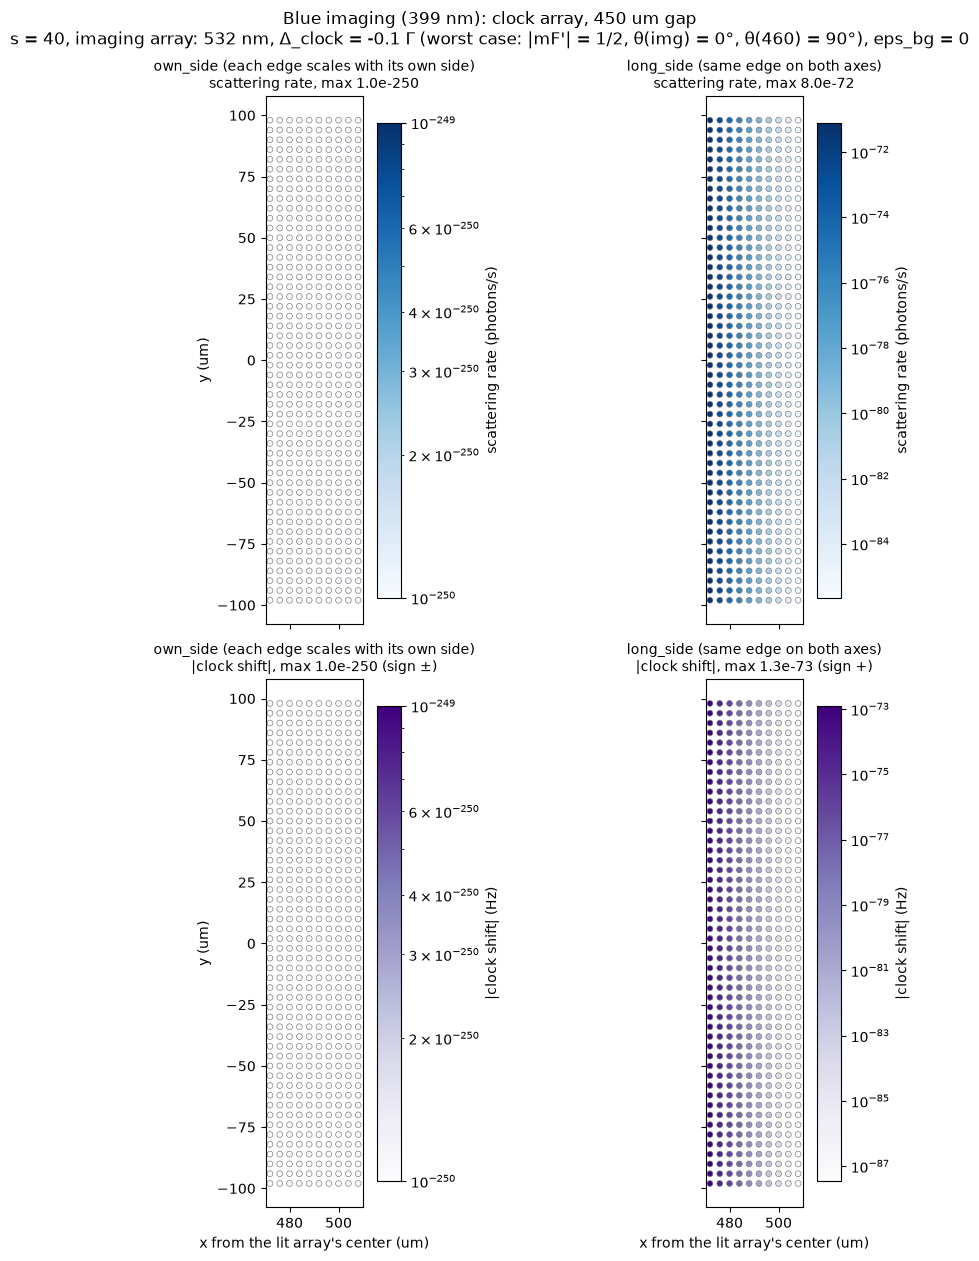

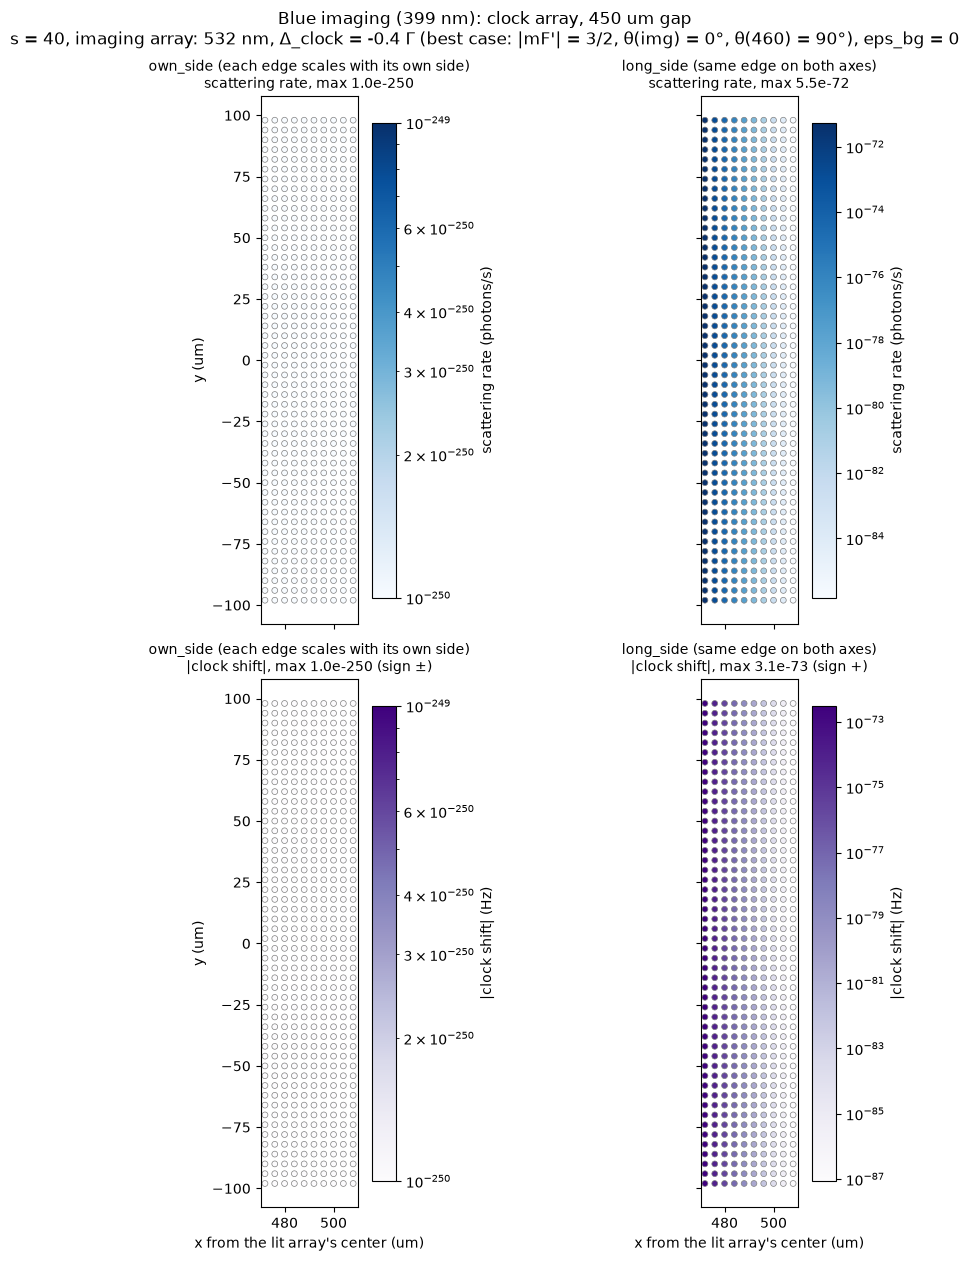

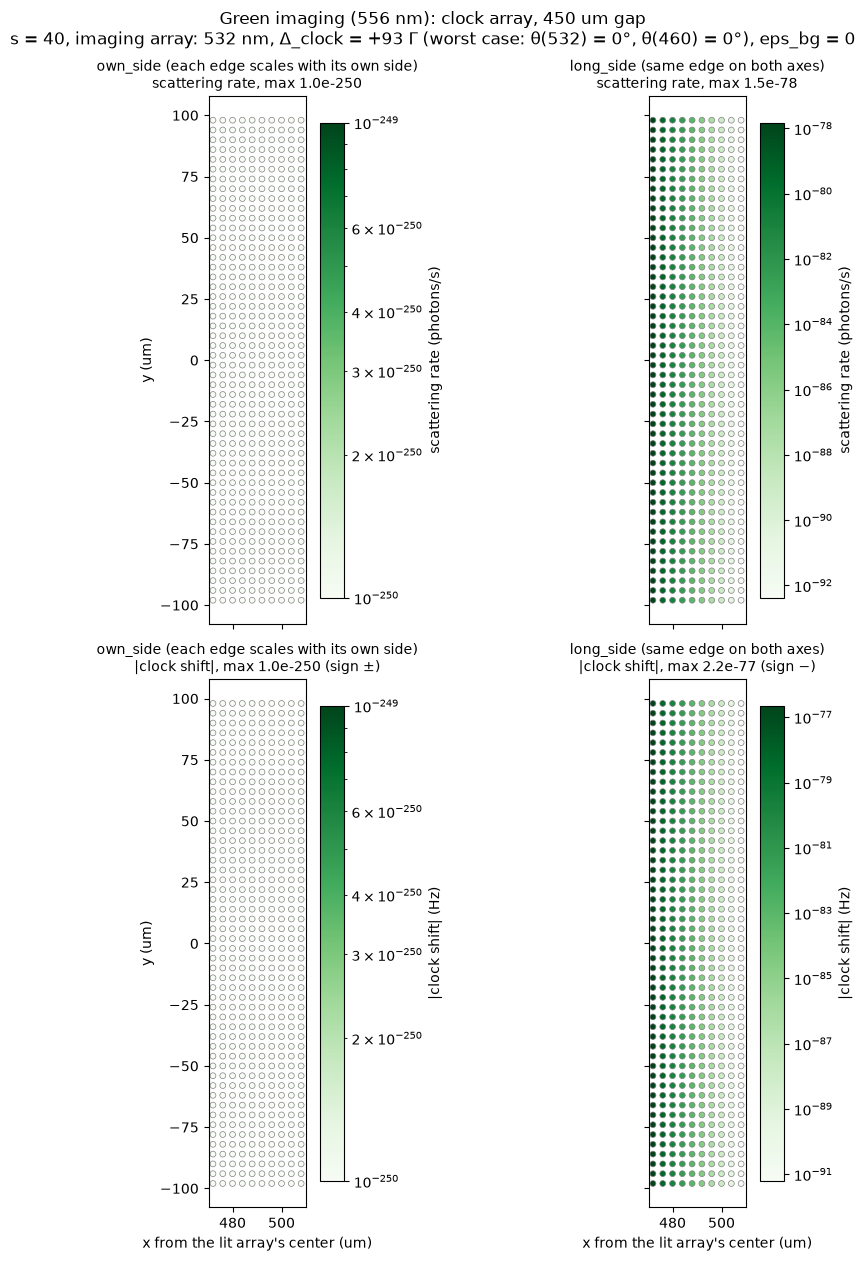

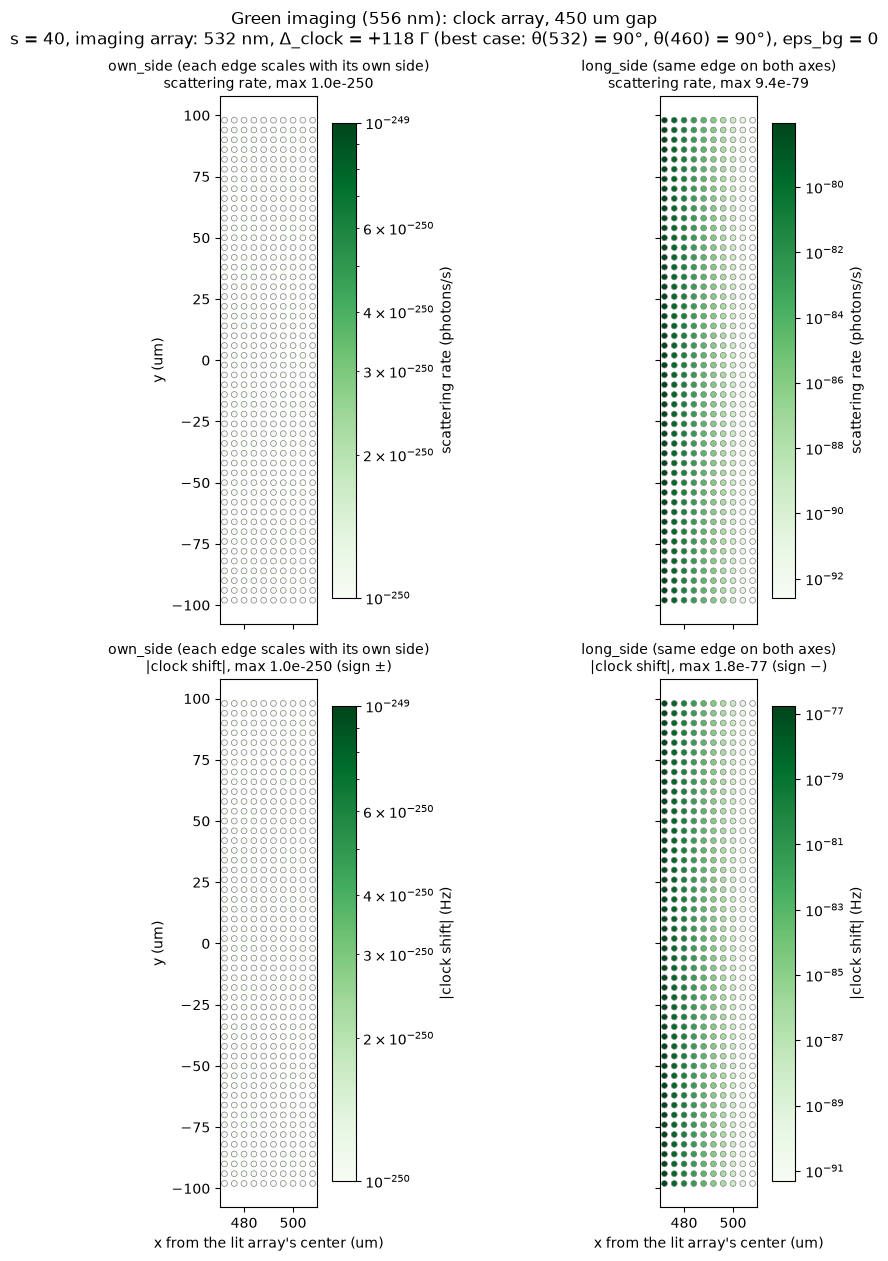

In [26]:
cases = {"own_side": "own_side (each edge scales with its own side)",
         "long_side": "long_side (same edge on both axes)"}

def plot_maps(task):
    '''2x2 maps of the clock array for one task: rows = scattering rate, |clock shift|; columns = edge case.'''
    quantities = [("rate", task["cmap"], "scattering rate (photons/s)"),
                  ("shift", task["shift_cmap"], "|clock shift| (Hz)")]
    Xt, Yt = task["X_clock"], task["Y_clock"]   # clock sites, measured from the center of the array the light shines on
    dot = 110 * min(1, 20/Yt.shape[0])**2       # smaller dots for taller arrays
    fig, axes = plt.subplots(2, 2, figsize=(8.5, 12.5), sharex=True, sharey=True, layout="constrained")
    invalid_handle = None
    for col, (case, case_label) in enumerate(cases.items()):
        rate, shift, s_sites = clock_effects(tophat_fraction(task, case, eps_bg), task)
        values = {"rate": rate, "shift": np.abs(shift)}
        for row, (key, cmap, label) in enumerate(quantities):
            ax = axes[row, col]
            vals = np.maximum(values[key], 1e-250)    # far tail underflows to 0; keep it plottable on a log scale
            sc = ax.scatter(Xt*1e6, Yt*1e6, c=vals, cmap=cmap, norm=log_norm(vals.min(), vals.max()),
                            s=dot, edgecolors="0.5", linewidths=0.5)
            fig.colorbar(sc, ax=ax, label=label, shrink=0.9)
            title = f"{case_label}\n{label.split(' (')[0]}, max {vals.max():.1e}"
            if key == "shift":
                sign = "+" if np.all(shift > 0) else "−" if np.all(shift < 0) else "±"
                title += f" (sign {sign})"
                invalid = s_sites > 0.1          # shift formula assumes s << 1
                if invalid.any():
                    invalid_handle = ax.scatter(Xt[invalid]*1e6, Yt[invalid]*1e6, marker="x", c="k", s=40, lw=1,
                                                label="s > 0.1: shift formula not valid (atom saturated)")
            ax.set_title(title, fontsize=10)
            ax.set_aspect("equal")
    for ax in axes[-1]: ax.set_xlabel("x from the lit array's center (um)")
    for ax in axes[:, 0]: ax.set_ylabel("y (um)")
    if invalid_handle is not None:
        fig.legend(handles=[invalid_handle], loc="outside lower center")
    fig.suptitle(f"{task['name']}: clock array, {task['gap']*1e6:.0f} um gap\n{task['light_label']}, eps_bg = {eps_bg:g}")
    plt.show()

for task in tasks.values():
    plot_maps(task)

## Uniform background floor (`own_side`)

For `own_side` the designed edge reaches the clock array at less than $10^{-40}$ of peak, so any realistic leakage floor `eps_bg` sets everything there. There is one figure per task. Each column uses a different `eps_bg`; each row shares one color scale, so the panels compare directly. Because the floor is uniform, every site in a panel sees the same value (the printed tables list them, including the site-to-site spread). While $s \ll 1$ at the clock atoms, the scattering rate and clock shift both scale linearly with `eps_bg`.

Blue imaging (399 nm), own_side, s = 40, imaging array: 532 nm, Δ_clock = -0.1 Γ (worst case: |mF'| = 1/2, θ(img) = 0°, θ(460) = 90°)
  eps_bg  s at clock  rate (1/s)  per pulse  clock shift (Hz)  site-to-site spread
   1e-06     4.0e-05    3.52e+03      0.022              55.3              0.0e+00
   1e-05     4.0e-04    3.52e+04       0.22               553              0.0e+00
   1e-04     4.0e-03    3.51e+05        2.2          5.53e+03              0.0e+00
   1e-03     4.0e-02    3.39e+06         21          5.53e+04              0.0e+00


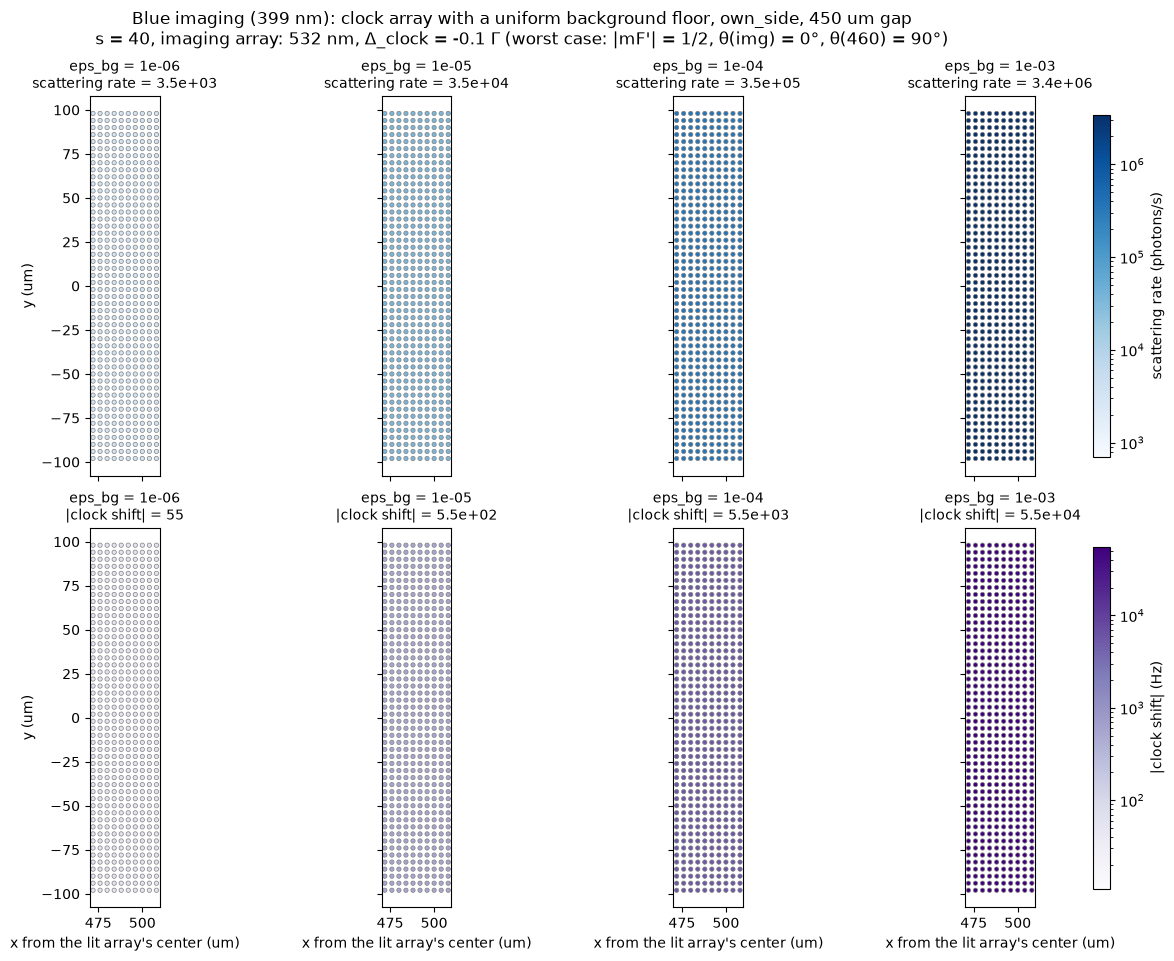

Blue imaging (399 nm), own_side, s = 40, imaging array: 532 nm, Δ_clock = -0.4 Γ (best case: |mF'| = 3/2, θ(img) = 0°, θ(460) = 90°)
  eps_bg  s at clock  rate (1/s)  per pulse  clock shift (Hz)  site-to-site spread
   1e-06     4.0e-05    2.42e+03      0.015               138              0.0e+00
   1e-05     4.0e-04    2.42e+04       0.15          1.38e+03              0.0e+00
   1e-04     4.0e-03    2.42e+05        1.5          1.38e+04              0.0e+00
   1e-03     4.0e-02    2.36e+06         15          1.38e+05              0.0e+00


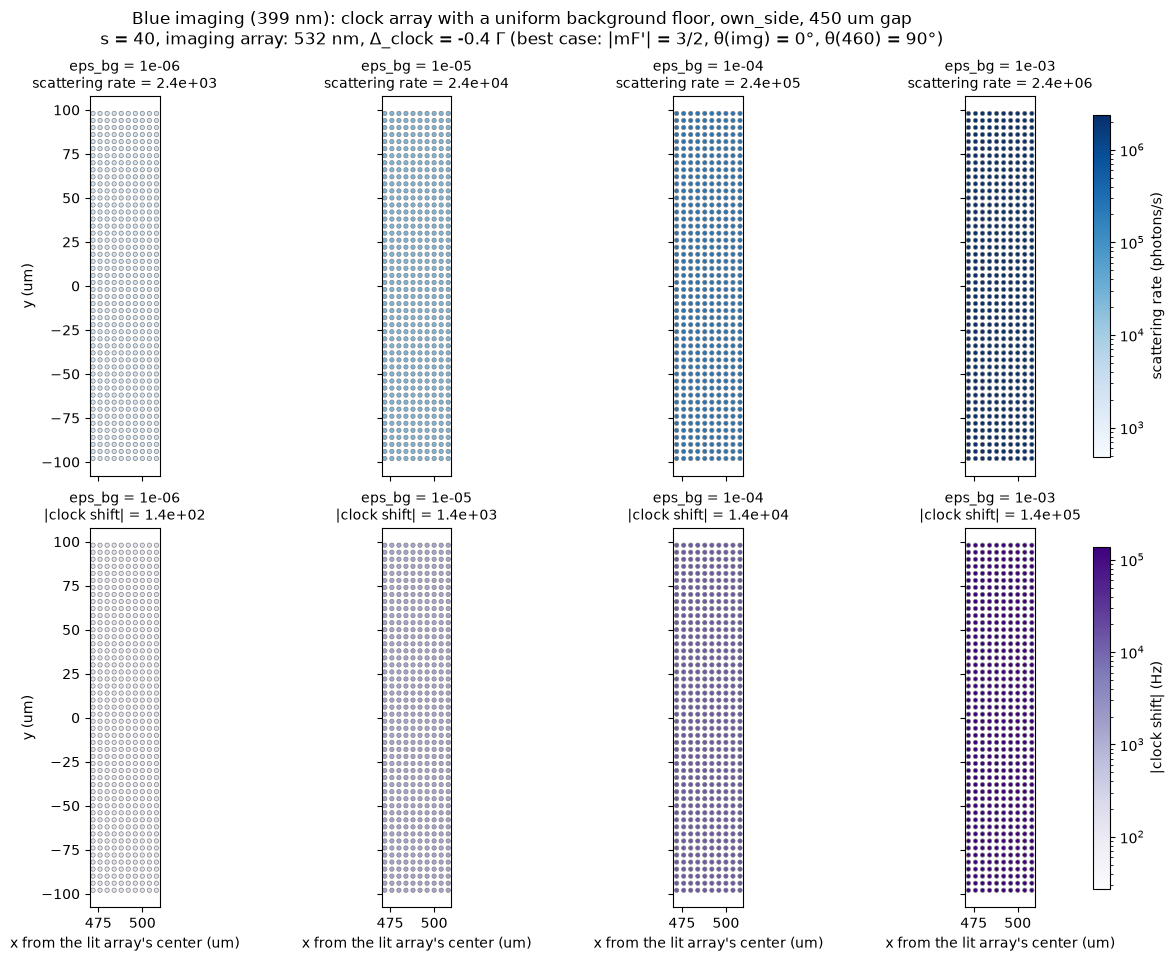

Green imaging (556 nm), own_side, s = 40, imaging array: 532 nm, Δ_clock = +93 Γ (worst case: θ(532) = 0°, θ(460) = 0°)
  eps_bg  s at clock  rate (1/s)  per pulse  clock shift (Hz)  site-to-site spread
   1e-06     4.0e-05    6.64e-04    2.7e-06          -0.00983              0.0e+00
   1e-05     4.0e-04    6.64e-03    2.7e-05           -0.0983              0.0e+00
   1e-04     4.0e-03    6.64e-02    0.00027            -0.983              0.0e+00
   1e-03     4.0e-02    6.64e-01     0.0027             -9.83              0.0e+00


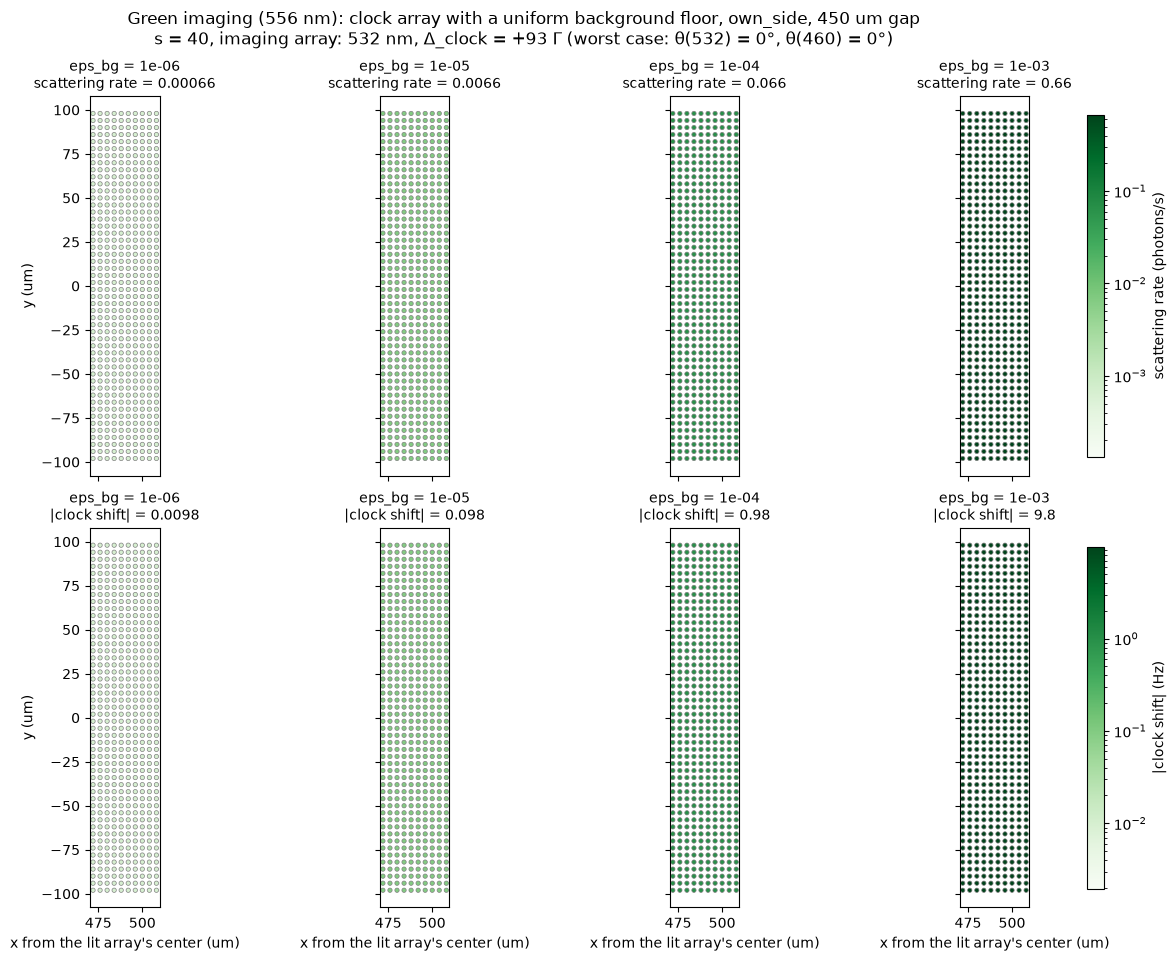

Green imaging (556 nm), own_side, s = 40, imaging array: 532 nm, Δ_clock = +118 Γ (best case: θ(532) = 90°, θ(460) = 90°)
  eps_bg  s at clock  rate (1/s)  per pulse  clock shift (Hz)  site-to-site spread
   1e-06     4.0e-05    4.12e-04    1.6e-06          -0.00775              0.0e+00
   1e-05     4.0e-04    4.12e-03    1.6e-05           -0.0775              0.0e+00
   1e-04     4.0e-03    4.12e-02    0.00016            -0.775              0.0e+00
   1e-03     4.0e-02    4.12e-01     0.0016             -7.75              0.0e+00


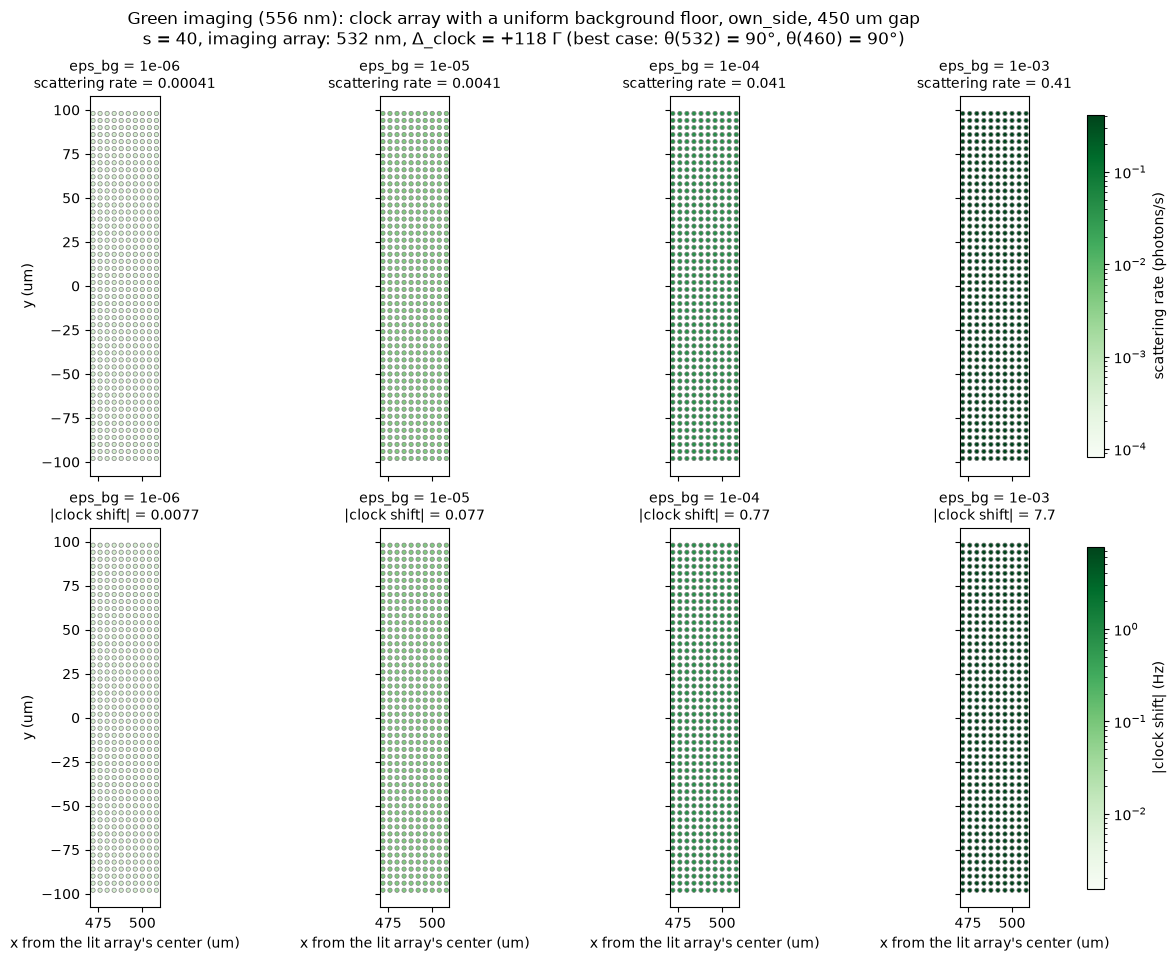

In [27]:
eps_bg_values = [1e-6, 1e-5, 1e-4, 1e-3]    # background floor, fraction of peak intensity
case = "own_side"

def plot_eps_sweep(task):
    '''Table and 2 x len(eps_bg_values) maps (scattering rate, |clock shift|) for one task.'''
    Xt, Yt = task["X_clock"], task["Y_clock"]
    dot = 60 * min(1, 20/Yt.shape[0])**2        # smaller dots for taller arrays
    results = {e: clock_effects(tophat_fraction(task, case, e), task) for e in eps_bg_values}

    # summary table: with own_side the designed edge is < 1e-40 at the clock array, so the floor sets everything
    print(f"{task['name']}, {case}, {task['light_label']}")
    print(f"{'eps_bg':>8} {'s at clock':>11} {'rate (1/s)':>11} {'per pulse':>10} {'clock shift (Hz)':>17} {'site-to-site spread':>20}")
    for e, (rate, shift, s_sites) in results.items():
        print(f"{e:>8.0e} {s_sites.max():>11.1e} {rate.max():>11.2e} {rate.max()*task['tau']:>10.2g} {shift.max():>17.3g} "
              f"{np.ptp(rate)/rate.max():>20.1e}")

    fig, axes = plt.subplots(2, len(eps_bg_values), figsize=(13, 9.5), sharex=True, sharey=True, layout="constrained")
    invalid_handle = None
    for row, (idx, cmap, label) in enumerate([(0, task["cmap"], "scattering rate (photons/s)"),
                                              (1, task["shift_cmap"], "|clock shift| (Hz)")]):
        row_vals = [np.abs(results[e][idx]) for e in eps_bg_values]
        # one color scale shared across the row; start it a bit below the minimum so the lowest panel isn't white
        norm = log_norm(0.2*min(v.min() for v in row_vals), max(v.max() for v in row_vals))
        for col, (e, vals) in enumerate(zip(eps_bg_values, row_vals)):
            ax = axes[row, col]
            sc = ax.scatter(Xt*1e6, Yt*1e6, c=vals, cmap=cmap, norm=norm, s=dot, edgecolors="0.5", linewidths=0.5)
            ax.set_title(f"eps_bg = {e:.0e}\n{label.split(' (')[0]} = {vals.max():.2g}", fontsize=10)
            ax.set_aspect("equal")
            s_sites = results[e][2]
            if idx == 1 and (s_sites > 0.1).any():      # shift formula assumes s << 1
                invalid_handle = ax.scatter(Xt[s_sites > 0.1]*1e6, Yt[s_sites > 0.1]*1e6, marker="x", c="k", s=30, lw=1,
                                            label="s > 0.1: shift formula not valid (atom saturated)")
        fig.colorbar(sc, ax=axes[row, :], label=label, shrink=0.9)
    for ax in axes[-1]: ax.set_xlabel("x from the lit array's center (um)")
    for ax in axes[:, 0]: ax.set_ylabel("y (um)")
    if invalid_handle is not None:
        fig.legend(handles=[invalid_handle], loc="outside lower center")
    fig.suptitle(f"{task['name']}: clock array with a uniform background floor, {case}, {task['gap']*1e6:.0f} um gap\n"
                 f"{task['light_label']}")
    plt.show()

for task in tasks.values():
    plot_eps_sweep(task)

Falconi paper has 6.3us as the blue imaging time which I use.

The goal is to then have scattering rate for nearest atom, times 200, times 6.3us be something like 10^-3 or lower.

I can search over either parameters. (and over gaussian vs flat top zone to get this).

## Search over edge width and background floor

Requirement, worst case (every clock atom sees the nearest atom's light), per light pulse (one image):
$$N_{atoms}\,\tau \sum_k R_{sc,k}(\text{nearest}) < p_{max}$$

(to be clear nearest means we take the closest clock atom to the imaging array as worst case scenario )
with $N_{atoms}$ = 500 clock atoms, $p_{max} = 10^{-3}$ for both tasks, each task's own pulse length τ (6.3 μs, 4 ms), and the sum running over that task's couplings (one each here).

Since $s \ll 1$ at the clock atoms, each rate is linear in intensity, so the requirement becomes one intensity budget at the nearest atom:
$$f_{edge}(d) + \epsilon_{bg} < \epsilon_{max} = \frac{p_{max}}{N_{atoms}\,\tau \sum_k (\Gamma/2)\, s_k / (1 + x_k^2)}, \qquad x_k = \frac{2\Delta_k}{\Gamma}.$$
Here $d$ is the distance from the flat region's edge (20 μm (half the width, center is defined as 0)) to the nearest clock column: 452 μm for both tasks. $f_{edge}$ comes from model A, the erf top-hat (vendor shape), parameterized by its 10–90% edge width (the same optics for every task).

For both imaging tasks, the imaged atoms' own scattered light can be added on top (`include_fluorescence`, below the edge models). In the plots, the shading and black curves are the leaked beam alone, and the red curve is the real boundary, where the beam plus the fluorescence reaches p_max; it is missing when the fluorescence alone is over p_max.

In [28]:
# requirement (worst case): every clock atom sees the nearest atom's light
p_max = 1e-3                  # allowed expected scattered photons, summed over the clock array, per light pulse

def photons_per_image(frac, task):
    '''Expected scattered photons summed over the clock array during one light pulse (an image),
    if all the task's clock atoms see intensity fraction frac (of the peak), like the nearest one.'''
    return task["N_atoms"] * task["tau"] * sum(scatter_rate(frac*s_k, d_k, task["Gamma"]) for s_k, d_k in task["couplings"])

def intensity_budget(task):
    '''Largest intensity fraction at the nearest atom that keeps photons_per_image below p_max (s << 1 there).'''
    per_frac = sum(task["Gamma"]/2 * s_k/(1 + (2*d_k/task["Gamma"])**2) for s_k, d_k in task["couplings"])
    return p_max / (task["N_atoms"] * task["tau"] * per_frac)

for T in tasks.values():
    e_max = intensity_budget(T)
    print(f"{T['name']}: {T['N_atoms']} atoms x {T['tau']*1e3:g} ms, {T['light_label']}, p_max = {p_max:g}")
    print(f"    intensity budget at the nearest atom: eps_max = {e_max:.2e} of peak "
          f"(check: {photons_per_image(e_max, T):.4e} photons per pulse)")

Blue imaging (399 nm): 500 atoms x 0.0063 ms, s = 40, imaging array: 532 nm, Δ_clock = -0.1 Γ (worst case: |mF'| = 1/2, θ(img) = 0°, θ(460) = 90°), p_max = 0.001
    intensity budget at the nearest atom: eps_max = 9.01e-11 of peak (check: 1.0000e-03 photons per pulse)
Blue imaging (399 nm): 500 atoms x 0.0063 ms, s = 40, imaging array: 532 nm, Δ_clock = -0.4 Γ (best case: |mF'| = 3/2, θ(img) = 0°, θ(460) = 90°), p_max = 0.001
    intensity budget at the nearest atom: eps_max = 1.31e-10 of peak (check: 1.0000e-03 photons per pulse)
Green imaging (556 nm): 500 atoms x 4 ms, s = 40, imaging array: 532 nm, Δ_clock = +93 Γ (worst case: θ(532) = 0°, θ(460) = 0°), p_max = 0.001
    intensity budget at the nearest atom: eps_max = 7.53e-07 of peak (check: 1.0000e-03 photons per pulse)
Green imaging (556 nm): 500 atoms x 4 ms, s = 40, imaging array: 532 nm, Δ_clock = +118 Γ (best case: θ(532) = 90°, θ(460) = 90°), p_max = 0.001
    intensity budget at the nearest atom: eps_max = 1.21e-06 of peak

In [29]:
x_flat_edge = W_x/2                        # edge of the flat region, m (20 um)
x_nearest = X.min()                        # nearest clock column, m (67 um); those sites sit near y = 0,
                                           # deep inside the 160 um flat region in y, so the y-factor is ~1
edge_offset = (a_fit - 105) / sigma_fit    # vendor fit: 50% point sits ~2.0 sigma outside the flat region

def edge_A(x, edge_10_90):
    '''Model A (erf top-hat, vendor shape): intensity fraction at x for a 10-90% edge width edge_10_90 (m).'''
    sigma_e = edge_10_90 / 2.563
    return tophat_1d(x, x_flat_edge + edge_offset*sigma_e, sigma_e)

# consistency check: model A at the two old edge cases vs the full-grid top-hat model
for case in ("own_side", "long_side"):
    edge_10_90 = 2.563 * tophat_edges(case)[1]
    grid_val = tophat_intensity(X, Y, case).max() / peak_intensity
    print(f"{case}: 10-90% edge {edge_10_90*1e6:.1f} um -> model A {edge_A(x_nearest, edge_10_90):.3e}, full grid {grid_val:.3e}")

own_side: 10-90% edge 7.8 um -> model A 7.638e-41, full grid 7.638e-41
long_side: 10-90% edge 31.4 um -> model A 3.443e-02, full grid 3.443e-02


### Light scattered by the imaged atoms

Each imaged atom scatters $R_{sc}$ photons/s (s = 40), and that light reaches the clock atoms directly, so neither the phase mask nor a knife can block it. A clock atom sees the flux of each imaged atom's dipole radiation and absorbs it with a cross section $\sigma$:
$$R_{clock} = \sigma \sum_{\text{imaged atoms}} R_{sc}\,\frac{3\sin^2\theta}{8\pi r^2}, \qquad \sigma \le \sigma_0 = \frac{3\lambda^2}{2\pi}$$
$r$ is the distance from the imaged atom and θ the angle between its dipole and the line to the clock atom; the pattern integrates to 1 over all directions.

Worst case: all 500 imaging sites filled, and `fluor_dipole`(fluorescence dipole) along z (out of the array plane), so $\sin^2\theta = 1$ at every clock atom.

The cross section is set per color by `fluor_detuned` (fluorescence detuned):
- Blue (`False`): $\sigma_0$, which assumes the clock atoms are resonant with the light and polarization-matched. They nearly are: with the imaging array in 532 nm tweezers or in free space, Δ_clock is only 0.1–0.3 Γ, so the detuning factor below would lower it only 4–26%
- Green (`True`): the clock atoms sit 93–118 Γ from the imaging light (the tweezer shifts above), so $\sigma_0$ would overstate it about 10⁴×. `absorption_factor` scales it by the same detuning factor as `scatter_rate`: $\sigma = \sigma_0/(1 + x^2)$ with $x = 2\Delta_{clock}/\Gamma$, which gives (1.8–2.9) × 10⁻⁵ σ₀

This treats the imaged atoms' light as sitting at the laser frequency. At s = 40 it is actually spread over a few Γ, which would lower blue's real absorption (roughly 3×) and raise green's (roughly 2×).

A second layer: each photon a clock atom scatters can be absorbed by another clock atom. The light leaves it with the same dipole pattern, and the other clock atoms absorb it with the same cross section (they sit in the same tweezers, and a weakly driven atom scatters at the frequency it absorbed, so the light is as near resonance for them as for the first). With the first atom at the array's center, where its neighbours are closest (worst case), the rest of the array absorbs a fraction
$$f = \sigma \sum_{\text{other clock atoms}} \frac{3\sin^2\theta}{8\pi r^2}$$
of its light, and `include_rescattering` multiplies the photon count by $1 + f$. With $\sigma_0$, $f$ is only about 1% for blue (2% for green): even the nearest neighbour, 4 μm away, catches 6 × 10⁻⁴ of a blue photon, since $\sigma_0$ covers only 0.5% of the 16 μm² each site occupies. A third layer would be another factor $f$ smaller.

Left out: reabsorption inside the imaging array (would reduce it) and reflections off nearby surfaces (would add to it).

`include_fluorescence` adds the result to both imaging searches below, as photons per pulse on top of the leaked beam.

In [30]:
# light scattered by the imaged atoms: it reaches the clock atoms directly, so no beam shaping blocks it
include_fluorescence = True                  # add it to the imaging searches below
include_rescattering = True                  # also count the clock atoms scattering that light again, onto each other
fluor_detuned = {"blue": False,              # False: the clock atoms absorb with the resonant sigma_0 (worst case);
                 "green": True}              # True: at their detuning from the imaging light (absorption_factor)
fluor_dipole = np.array([0.0, 0.0, 1.0])     # emitting dipole axis; x faces the clock array, z is out of the array plane
                                             # (z gives sin^2(theta) = 1 at every clock atom: worst case)

def capture_fraction(task, dx, dy):
    '''Fraction of one emitter's photons absorbed by an atom at (dx, dy) from it (m, both in the plane z = 0): the flux
    3 sin^2(theta) / (8 pi r^2) per emitted photon, times the resonant cross section 3 lambda^2 / 2 pi.'''
    sigma_0 = 3*(2*pi*c/task["t"].omega)**2 / (2*pi)
    r2 = dx**2 + dy**2
    d = fluor_dipole / np.linalg.norm(fluor_dipole)
    sin2 = 1 - (dx*d[0] + dy*d[1])**2 / r2
    return sigma_0 * 3*sin2 / (8*pi*r2)

def fluorescence_rate(task, Xc, Yc):
    '''Photons/s scattered by clock atoms at (Xc, Yc) (m, from the imaging array's center) from the light of the imaged atoms
    (every site of the task's lit array filled).'''
    R_img = scatter_rate(*task["imaging"], task["Gamma"])                  # photons/s per imaged atom
    dx = Xc.reshape(-1, 1) - task["X_lit"].reshape(1, -1)                  # clock sites x imaged atoms
    dy = Yc.reshape(-1, 1) - task["Y_lit"].reshape(1, -1)
    return (R_img * capture_fraction(task, dx, dy).sum(axis=1)).reshape(Xc.shape)

def rescatter_fraction(task):
    '''Fraction of one clock atom's scattered photons absorbed by the other clock atoms, for the atom nearest the array's
    center (the closest neighbours: worst case). Same dipole pattern and sigma_0: the clock atoms all sit in the same
    tweezers, so the light one of them scatters is as near resonance for the others as it was for it.'''
    x, y = task["X_clock"].ravel(), task["Y_clock"].ravel()
    i = np.argmin((x - x.mean())**2 + (y - y.mean())**2)
    others = np.arange(x.size) != i
    return capture_fraction(task, x[others] - x[i], y[others] - y[i]).sum()

def absorption_factor(task):
    '''Cross section / sigma_0 for the task's clock atoms absorbing the imaged atoms' light, taken to sit at the imaging
    laser's frequency, Delta_clock (the task's coupling) from their line: 1/(1 + x^2), x = 2 Delta_clock / Gamma,
    the same detuning factor as in scatter_rate.'''
    return 1/(1 + (2*task["couplings"][0][1]/task["Gamma"])**2)

def fluorescence_per_pulse(task, gap, detuned=False, rescatter=None):
    '''Photons per pulse on the whole clock array, moved to this gap; worst case like the search: every clock atom gets the
    worst site's rate. detuned scales sigma_0 by absorption_factor. rescatter (default include_rescattering) adds one more
    layer: each of those photons is scattered again by the clock array with probability rescatter_fraction (times
    absorption_factor if detuned: the clock atoms scatter it elastically, so it is as far from their neighbours' line),
    so the count goes up by 1 + f.'''
    rescatter = include_rescattering if rescatter is None else rescatter
    a = absorption_factor(task) if detuned else 1.0
    Xc = task["X_clock"] + gap - task["gap"]
    layers = 1 + (a*rescatter_fraction(task) if rescatter else 0.0)
    return layers * a * task["N_atoms"] * task["tau"] * fluorescence_rate(task, Xc, task["Y_clock"]).max()

P_fluor = {}                                                        # photons per pulse added to each task's search
for key, T in tasks.items():
    if T["imaging"] is None:
        continue
    detuned = fluor_detuned[key.split("_")[0]]
    a = absorption_factor(T) if detuned else 1.0
    R_img = scatter_rate(*T["imaging"], T["Gamma"])
    R_fl = a * fluorescence_rate(T, T["X_clock"], T["Y_clock"])
    P_fl1 = fluorescence_per_pulse(T, T["gap"], detuned, rescatter=False)     # first layer: light from the imaged atoms
    f_re = a * rescatter_fraction(T)
    P_fl = fluorescence_per_pulse(T, T["gap"], detuned)                       # plus the re-scattering layer, if included
    P_fluor[key] = P_fl if include_fluorescence else 0.0
    print(f"{key}: {T['X_lit'].size} imaged atoms, each scattering {R_img:.2e} photons/s = {R_img*T['tau']:.0f} photons per image; "
          + (f"absorbed at Δ_clock = {T['couplings'][0][1]/T['Gamma']:+.1f} Γ: {a:.2g} x sigma_0" if detuned else "absorbed with sigma_0"))
    print(f"    clock atoms ({T['gap']*1e6:.0f} um gap) scatter {R_fl.min():.4g} to {R_fl.max():.4g} photons/s of that light")
    print(f"    photons per image on the whole clock array: {P_fl1:.2g} (worst site x {T['N_atoms']}; {T['tau']*R_fl.sum():.2g} summed over sites), "
          f"{P_fl1/p_max:.4g} x p_max")
    print(f"    re-scattering: each photon a clock atom scatters is absorbed by another clock atom with probability {f_re:.2g} "
          f"(from the array's center; the nearest neighbour alone: {a*capture_fraction(T, pitch, 0.0):.1e})")
    print(f"        adds {f_re*P_fl1:.2g} photons per image ({f_re*P_fl1/p_max:.2g} x p_max)"
          + (f", for {P_fl:.3g} in all" if include_rescattering else "; not included (include_rescattering = False)"))
    if P_fl > p_max:
        gap_ok = brentq(lambda g: fluorescence_per_pulse(T, g, detuned) - p_max, T["gap"], 1.0)
        print(f"    the fluorescence alone stays under p_max = {p_max:g} only for a gap above {gap_ok*1e3:.2f} mm")
print("included in the imaging searches below" if include_fluorescence
      else "not included in the searches below (include_fluorescence = False)")

blue_imaging: 500 imaged atoms, each scattering 8.93e+07 photons/s = 562 photons per image; absorbed with sigma_0
    clock atoms (450 um gap) scatter 1499 to 1794 photons/s of that light
    photons per image on the whole clock array: 5.7 (worst site x 500; 5.2 summed over sites), 5650 x p_max
    re-scattering: each photon a clock atom scatters is absorbed by another clock atom with probability 0.0092 (from the array's center; the nearest neighbour alone: 5.7e-04)
        adds 0.052 photons per image (52 x p_max), for 5.7 in all
    the fluorescence alone stays under p_max = 0.001 only for a gap above 35.85 mm
blue_imaging_best: 500 imaged atoms, each scattering 8.93e+07 photons/s = 562 photons per image; absorbed with sigma_0
    clock atoms (450 um gap) scatter 1499 to 1794 photons/s of that light
    photons per image on the whole clock array: 5.7 (worst site x 500; 5.2 summed over sites), 5650 x p_max
    re-scattering: each photon a clock atom scatters is absorbed by another clo

In [31]:
from scipy.optimize import brentq

eps_grid = np.logspace(-14, -1, 131)              # background floor, fraction of peak
search = {}
for key, T in tasks.items():
    d_near = T["x_nearest"] - x_flat_edge
    widths = np.linspace(0.5e-6, 0.8*d_near, 160)   # m; model A: 10-90% edge width
    W_grid, E_grid = np.meshgrid(widths, eps_grid)
    P_add = P_fluor.get(key, 0.0)                     # photons per pulse from the imaged atoms' light (if included)
    e_max = intensity_budget(T) * (1 - P_add/p_max)   # what's left of the intensity budget for the leaked beam
    print(f"{T['name']} (nearest clock atom {d_near*1e6:.0f} um past the flat edge):")
    if P_add > 0:
        print(f"    imaged atoms' fluorescence: {P_add:.2g} photons per pulse ({P_add/p_max:.3g} x p_max)")
    A_max = None
    if e_max > 0:
        # the two ends of the boundary: no background at all, or a perfectly sharp edge
        # (search edges up to the gap itself: an edge that wide puts > 10% of the peak on the nearest atom)
        A_max = brentq(lambda w: edge_A(T["x_nearest"], w) - e_max, 1e-7, d_near)
        print(f"    with no background:          model A needs a 10-90% edge < {A_max*1e6:.1f} um")
        print(f"    with a perfectly sharp edge: background floor eps_bg < {e_max:.1e}")
    else:
        print("    nothing works: the fluorescence alone is over p_max")
    search[key] = dict(widths=widths, eps_max=e_max, A_max=A_max, P_add=P_add,   # P_A: leaked beam alone
                       P_A=photons_per_image(edge_A(T["x_nearest"], W_grid) + E_grid, T))

Blue imaging (399 nm) (nearest clock atom 452 um past the flat edge):
    imaged atoms' fluorescence: 5.7 photons per pulse (5.7e+03 x p_max)
    nothing works: the fluorescence alone is over p_max
Blue imaging (399 nm) (nearest clock atom 452 um past the flat edge):
    imaged atoms' fluorescence: 5.7 photons per pulse (5.7e+03 x p_max)
    nothing works: the fluorescence alone is over p_max
Green imaging (556 nm) (nearest clock atom 452 um past the flat edge):
    imaged atoms' fluorescence: 0.0012 photons per pulse (1.15 x p_max)
    nothing works: the fluorescence alone is over p_max
Green imaging (556 nm) (nearest clock atom 452 um past the flat edge):
    imaged atoms' fluorescence: 0.00071 photons per pulse (0.715 x p_max)
    with no background:          model A needs a 10-90% edge < 165.9 um
    with a perfectly sharp edge: background floor eps_bg < 3.5e-07


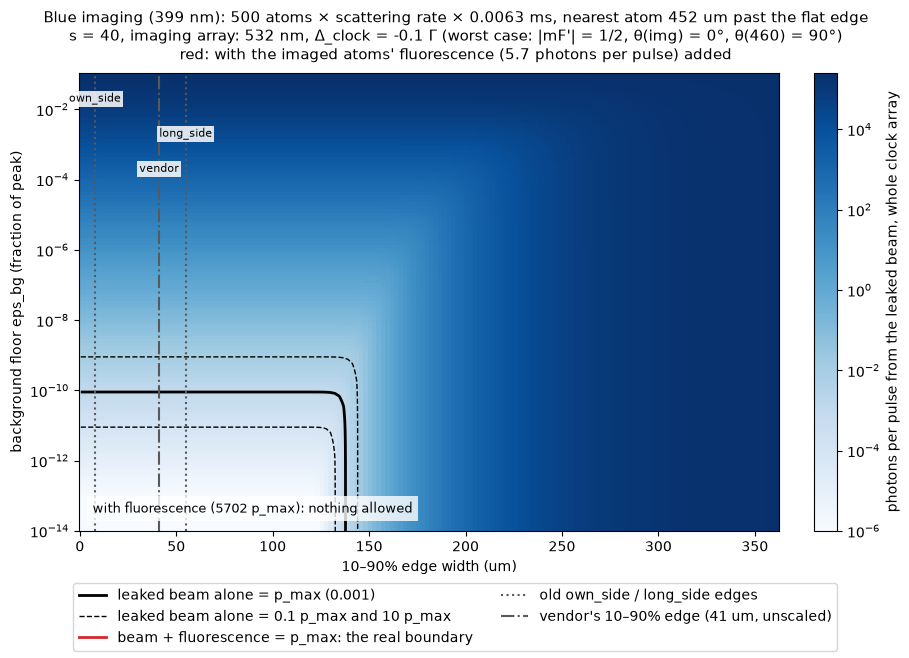

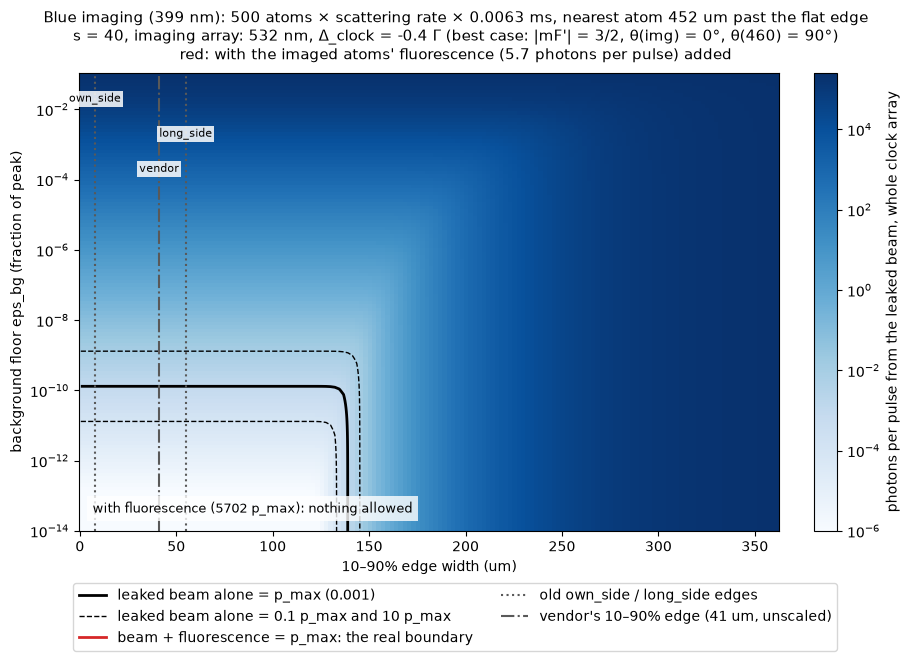

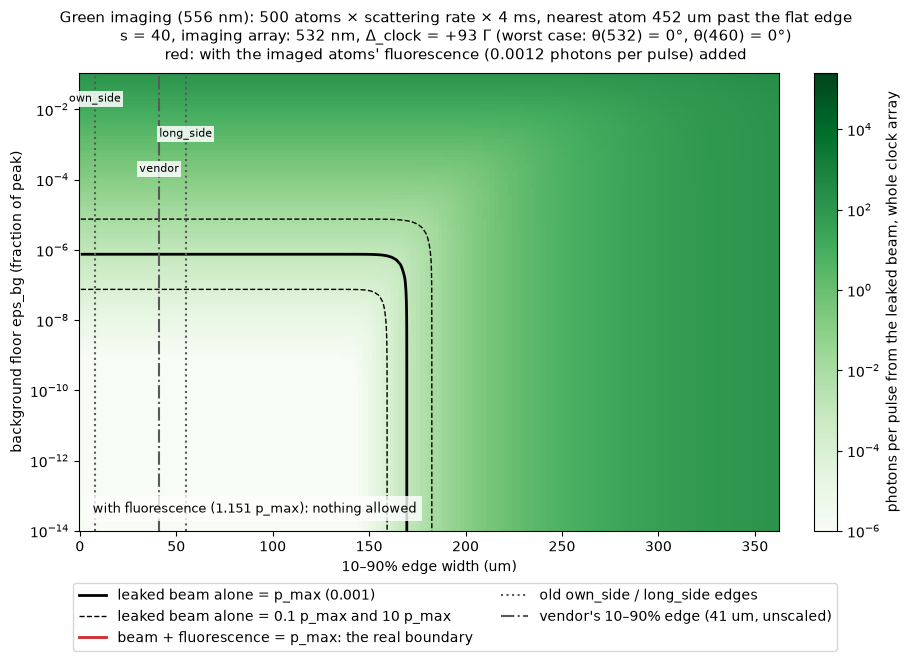

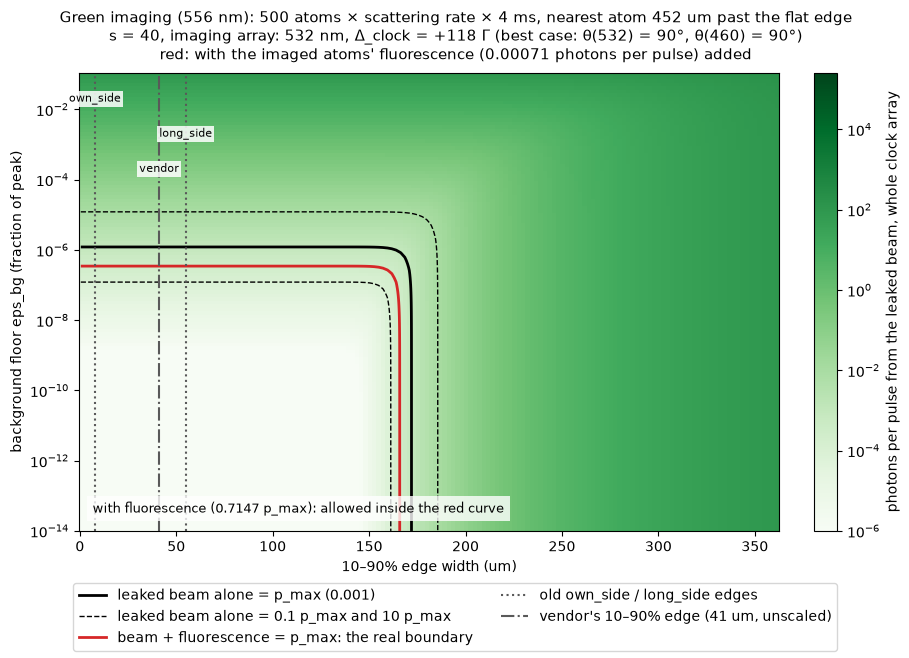

In [32]:
from matplotlib.lines import Line2D

P_top = max(r["P_A"].max() for r in search.values())   # same color scale for every task (leaked beam)

def plot_search(key):
    '''Edge width x background map (model A) of the photons the leaked beam scatters per pulse, for one task.
    Shading and black curves: the leaked beam alone. Red: p_max for the beam plus the imaged atoms' fluorescence.'''
    T, r = tasks[key], search[key]
    fig, ax = plt.subplots(figsize=(9, 6.5), layout="constrained")
    P = r["P_A"]
    mesh = ax.pcolormesh(r["widths"]*1e6, eps_grid, P, norm=LogNorm(1e-6, P_top), cmap=T["cmap"], shading="auto")
    for levels, lw, ls in (([p_max], 2, "-"), ([0.1*p_max, 10*p_max], 1, "--")):
        levels = [lev for lev in levels if P.min() < lev < P.max()]       # skip levels the map never reaches
        if levels:
            ax.contour(r["widths"]*1e6, eps_grid, P, levels=levels, colors="k", linewidths=lw, linestyles=ls)
    P_tot = P + r["P_add"]
    if r["P_add"] > 0 and P_tot.min() < p_max:
        ax.contour(r["widths"]*1e6, eps_grid, P_tot, levels=[p_max], colors="tab:red", linewidths=2)
    if r["P_add"] == 0:
        note = "allowed" if P.min() < p_max else "nothing allowed"
    else:
        note = (f"with fluorescence ({r['P_add']/p_max:.4g} p_max): "
                + ("allowed inside the red curve" if P_tot.min() < p_max else "nothing allowed"))
    ax.text(0.02, 0.04, note, transform=ax.transAxes, fontsize=9, bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    ax.set_yscale("log"); ax.set_xlabel("10–90% edge width (um)")
    for case, y_text in (("own_side", 3e-2), ("long_side", 3e-3)):   # the two old edge cases, for reference
        ax.axvline(2.563*tophat_edges(case, T["W"])[1]*1e6, color="0.35", ls=":", lw=1.5)
        ax.text(2.563*tophat_edges(case, T["W"])[1]*1e6, y_text, case, fontsize=8, ha="center", va="top",
                bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.5))
    ax.axvline(2.563*sigma_fit, color="0.35", ls="-.", lw=1.5)   # the vendor's own edge (210 um flat region), unscaled
    ax.text(2.563*sigma_fit, 3e-4, "vendor", fontsize=8, ha="center", va="top",
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.5))
    ax.set_ylabel("background floor eps_bg (fraction of peak)")
    fig.colorbar(mesh, ax=ax, label="photons per pulse from the leaked beam, whole clock array")
    fig.legend(handles=[Line2D([], [], color="k", lw=2, label=f"leaked beam alone = p_max ({p_max:g})"),
                        Line2D([], [], color="k", lw=1, ls="--", label="leaked beam alone = 0.1 p_max and 10 p_max"),
                        Line2D([], [], color="tab:red", lw=2, label="beam + fluorescence = p_max: the real boundary"),
                        Line2D([], [], color="0.35", lw=1.5, ls=":", label="old own_side / long_side edges"),
                        Line2D([], [], color="0.35", lw=1.5, ls="-.", label=f"vendor's 10–90% edge ({2.563*sigma_fit:.0f} um, unscaled)")],
               loc="outside lower center", ncol=2)
    fig.suptitle(f"{T['name']}: {T['N_atoms']} atoms × scattering rate × {T['tau']*1e3:g} ms, nearest atom "
                 f"{(T['x_nearest'] - x_flat_edge)*1e6:.0f} um past the flat edge\n{T['light_label']}"
                 + (f"\nred: with the imaged atoms' fluorescence ({r['P_add']:.2g} photons per pulse) added" if r["P_add"] > 0 else ""), fontsize=11)
    plt.show()

for key in tasks:
    plot_search(key)